# 03b Feature distributions and group comparison

Exploratory description of extracted WESAD features. **No model fitting, feature selection, SHAP computation, or modification of input tables.** Displaying a requested feature list is not a selection step for a predictive model.

Conditions: baseline, stress, amusement. Windows overlap; descriptive window statistics do not represent independent observations. Participant–condition summaries give participants equal weight. Correlations are not causal evidence.

EDA tonic/SCR/rise-time variables in this project are **proxies**, not validated electrodermal decomposition. ECG interval variability and BVP pulse-interval variability are distinct constructs. 

In [7]:
from pathlib import Path
import json, hashlib, warnings
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis, spearmanr
from IPython.display import display, Markdown, Image

# Default requested inputs. For revision_v2 set ARTIFACTS_REL = 'artifacts/revision_v2'.
PROJECT_ROOT = None
ARTIFACTS_REL = 'artifacts'
SHOW_FIGURES = True
here=Path.cwd().resolve()
ROOT=Path(PROJECT_ROOT).resolve() if PROJECT_ROOT else next(
    (p for p in [here,*here.parents] if (p/'src').is_dir() and (p/'configs').is_dir()),None)
if ROOT is None:raise RuntimeError('Place the notebook inside the project or set PROJECT_ROOT.')
A=ROOT/ARTIFACTS_REL
DIST=A/'figures/distributions';GROUP=A/'figures/group_comparisons';CORR=A/'figures/correlations'
REPORT=A/'reports/feature_eda_report.md'
TABLES=A/'reports/feature_eda_tables'
for folder in [DIST,GROUP,CORR,REPORT.parent,TABLES]:folder.mkdir(parents=True,exist_ok=True)
paths={site:A/f'features/{site}_features.parquet' for site in ['chest','wrist','fused']}
paths.update(names=A/'features/feature_names.json',qc=A/'qc/signal_qc.csv')
for name,path in paths.items():
    if not path.is_file():raise FileNotFoundError(f'Missing input: {name}; check ARTIFACTS_REL.')
names=json.loads(paths['names'].read_text(encoding='utf-8'))
qc=pd.read_csv(paths['qc'])
raw={site:pd.read_parquet(paths[site]) for site in ['chest','wrist','fused']}
ORDER=['Baseline','Stress','Amusement'];LABELS={1:'Baseline',2:'Stress',3:'Amusement'}
sns.set_theme(style='whitegrid',context='notebook')
def boolean(series):
    s=series.astype(str).str.lower().str.strip()
    if not s.isin(['true','false']).all():raise ValueError('Invalid valid flags.')
    return s.eq('true')
data={}
for site,frame in raw.items():
    if frame.duplicated(['subject_id','window_id']).any():raise ValueError(f'Duplicate windows: {site}')
    f=frame.loc[frame.label.isin(LABELS)].copy()
    if 'valid' in f:f=f.loc[boolean(f.valid)].copy()
    f['condition']=pd.Categorical(f.label.map(LABELS),categories=ORDER,ordered=True)
    data[site]=f
def savefig(fig,path):
    fig.savefig(path,dpi=300,bbox_inches='tight')
    if SHOW_FIGURES:
        with BytesIO() as b:
            fig.savefig(b,format='png',dpi=90,bbox_inches='tight');png=b.getvalue()
        display(Image(data=png))
    plt.close(fig)
print('Inputs loaded. Only validity flags and finite values define descriptive availability.')


Inputs loaded. Only validity flags and finite values define descriptive availability.


## Requested features and availability

The exact available columns are reported below. Missing requested features are documented, never replaced with a differently defined metric. Units follow the extraction code: interval metrics in ms, pNN50 as a fraction, rates per minute. ACC units require confirmation against the original recording documentation; no conversion is guessed.

In [8]:
definitions=[
 ('EDA','mean','EDA mean','recorded EDA units'),
 ('EDA','tonic_proxy','EDA tonic level (proxy)','recorded EDA units'),
 ('EDA','scr_proxy_rate_per_minute','SCR peak rate (proxy)','peaks/min'),
 ('EDA','rise_time_proxy','SCR rise time (proxy)','s'),
 ('ECG','mean_hr','Mean heart rate','beats/min'),
 ('ECG','hrv_rmssd','RMSSD (ECG)','ms'),
 ('ECG','hrv_sdnn','SDNN (ECG)','ms'),
 ('ECG','hrv_pnn50','pNN50 (ECG)','fraction'),
 ('ECG','hrv_lf_hf','LF/HF (ECG)','ratio'),
 ('Resp','respiratory_rate','Respiratory rate','breaths/min'),
 ('Resp','amplitude_variability','Respiratory amplitude variability','native units'),
 ('Temp','mean','Temperature mean','°C'),
 ('Temp','slope_per_second','Temperature slope','°C/s'),
 ('ACC','activity_level','Activity level (ACC magnitude SD)','native ACC units'),
 ('ACC','movement_variance','Movement variance (sum across axes)','native ACC units squared'),
 ('BVP','mean_pulse_rate','Mean pulse rate (BVP)','pulses/min'),
 ('BVP','prv_rmssd','PRV RMSSD (BVP)','ms'),
]
catalog=[]
for site in ['chest','wrist']:
    for channel,suffix,label,unit in definitions:
        if (site=='chest' and channel=='BVP') or (site=='wrist' and channel in ['ECG','Resp']):continue
        actual_channel='TEMP' if site=='wrist' and channel=='Temp' else channel
        column=f'{site}__{actual_channel}__{suffix}'
        # Only explicit equivalent naming aliases for LF/HF, never compute it here.
        aliases=[column] if suffix!='hrv_lf_hf' else [column,f'{site}__ECG__hrv_lfhf',f'{site}__ECG__lf_hf']
        column=next((x for x in aliases if x in raw[site]),column)
        catalog.append(dict(site=site,column=column,label=label,unit=unit,
                            available=column in raw[site],listed=column in names.get(site,[])))
catalog=pd.DataFrame(catalog)
selected=catalog[catalog.available].copy()
catalog.to_csv(TABLES/'requested_feature_availability.csv',index=False)
display(catalog)
lookup={r.column:(r.label,r.unit) for r in catalog.itertuples()}
def pretty(col):
    if col in lookup:return f'{col.split("__")[0].title()} · {lookup[col][0]}'
    parts=col.split('__');return ' · '.join([parts[0].title(),*parts[1:]]).replace('_',' ')


,site,column,label,unit,available,listed
0,chest,chest__EDA__mean,EDA mean,recorded EDA units,True,True
1,chest,chest__EDA__tonic_proxy,EDA tonic level (proxy),recorded EDA units,True,True
2,chest,chest__EDA__scr_proxy_rate_per_minute,SCR peak rate (proxy),peaks/min,True,True
3,chest,chest__EDA__rise_time_proxy,SCR rise time (proxy),s,True,True
4,chest,chest__ECG__mean_hr,Mean heart rate,beats/min,True,True
5,chest,chest__ECG__hrv_rmssd,RMSSD (ECG),ms,True,True
6,chest,chest__ECG__hrv_sdnn,SDNN (ECG),ms,True,True
7,chest,chest__ECG__hrv_pnn50,pNN50 (ECG),fraction,True,True
8,chest,chest__ECG__hrv_lf_hf,LF/HF (ECG),ratio,False,False
9,chest,chest__Resp__respiratory_rate,Respiratory rate,breaths/min,True,True


## Distributions and descriptive summaries

Each figure contains histogram/KDE, a global boxplot, condition violins, participant boxplots, and participant–condition means. KDE is omitted for constant or insufficient data. No values are trimmed or winsorized. Tukey fences flag unusual values descriptively; they do not diagnose artifacts.

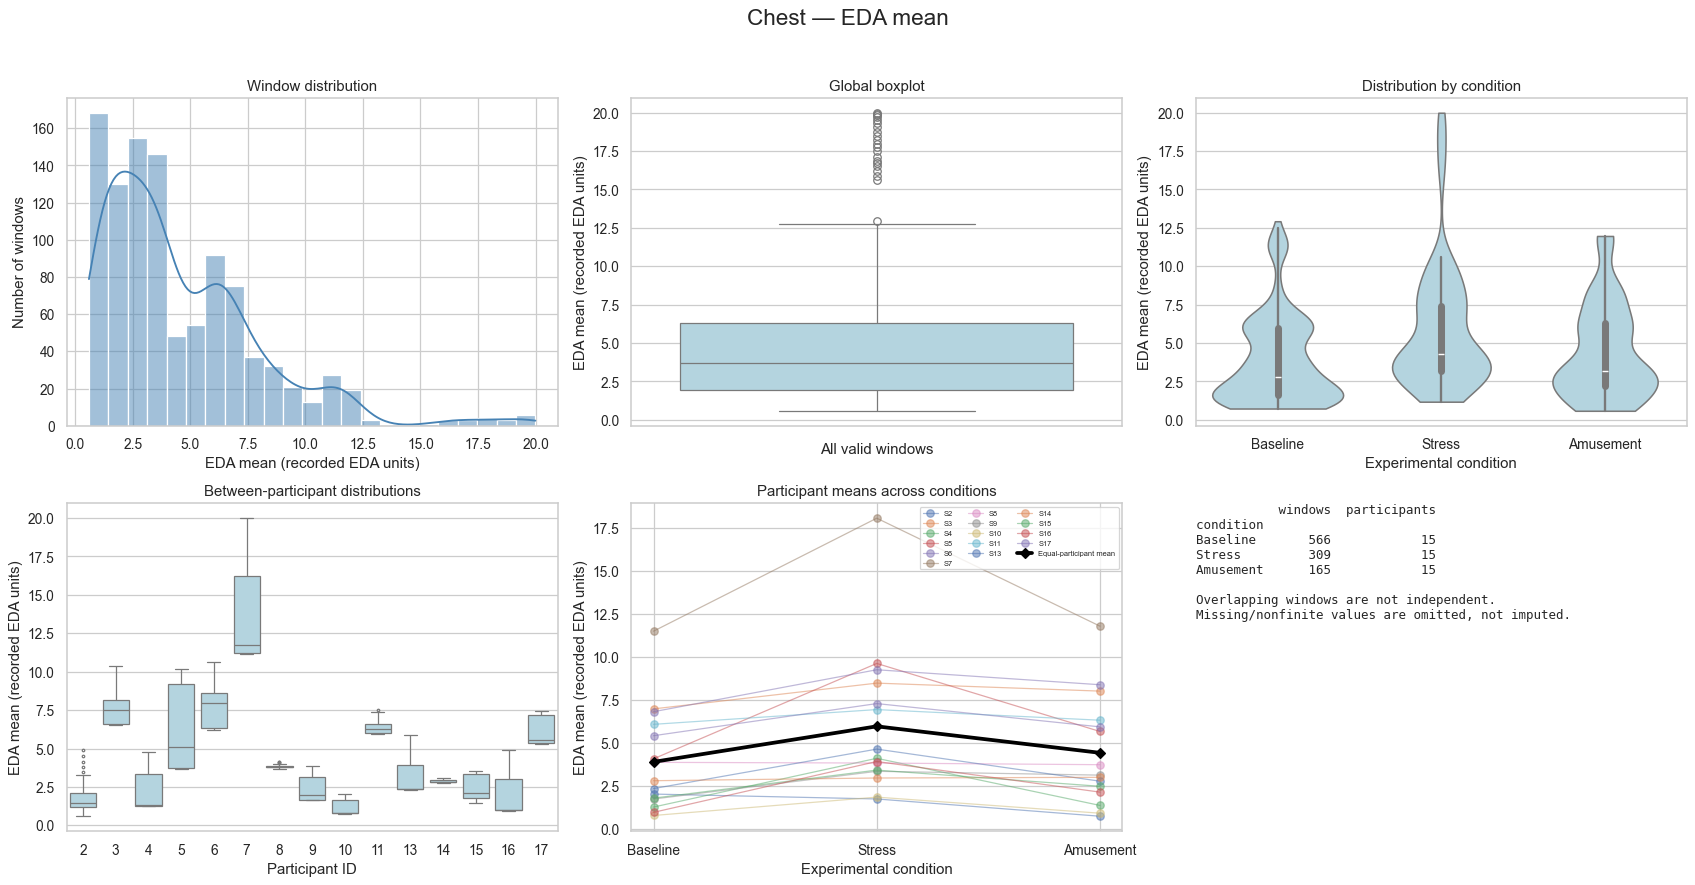

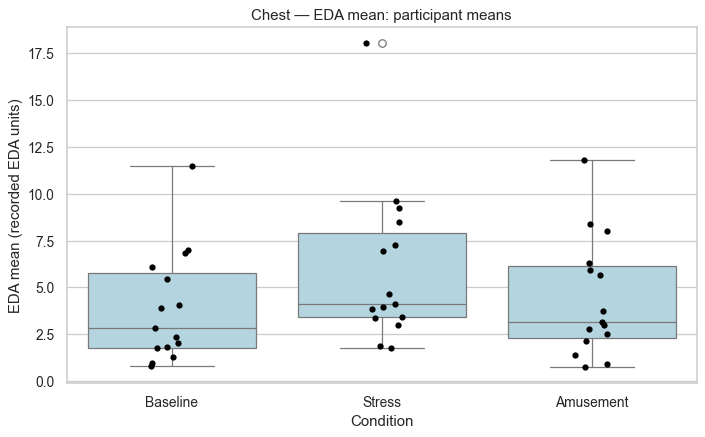

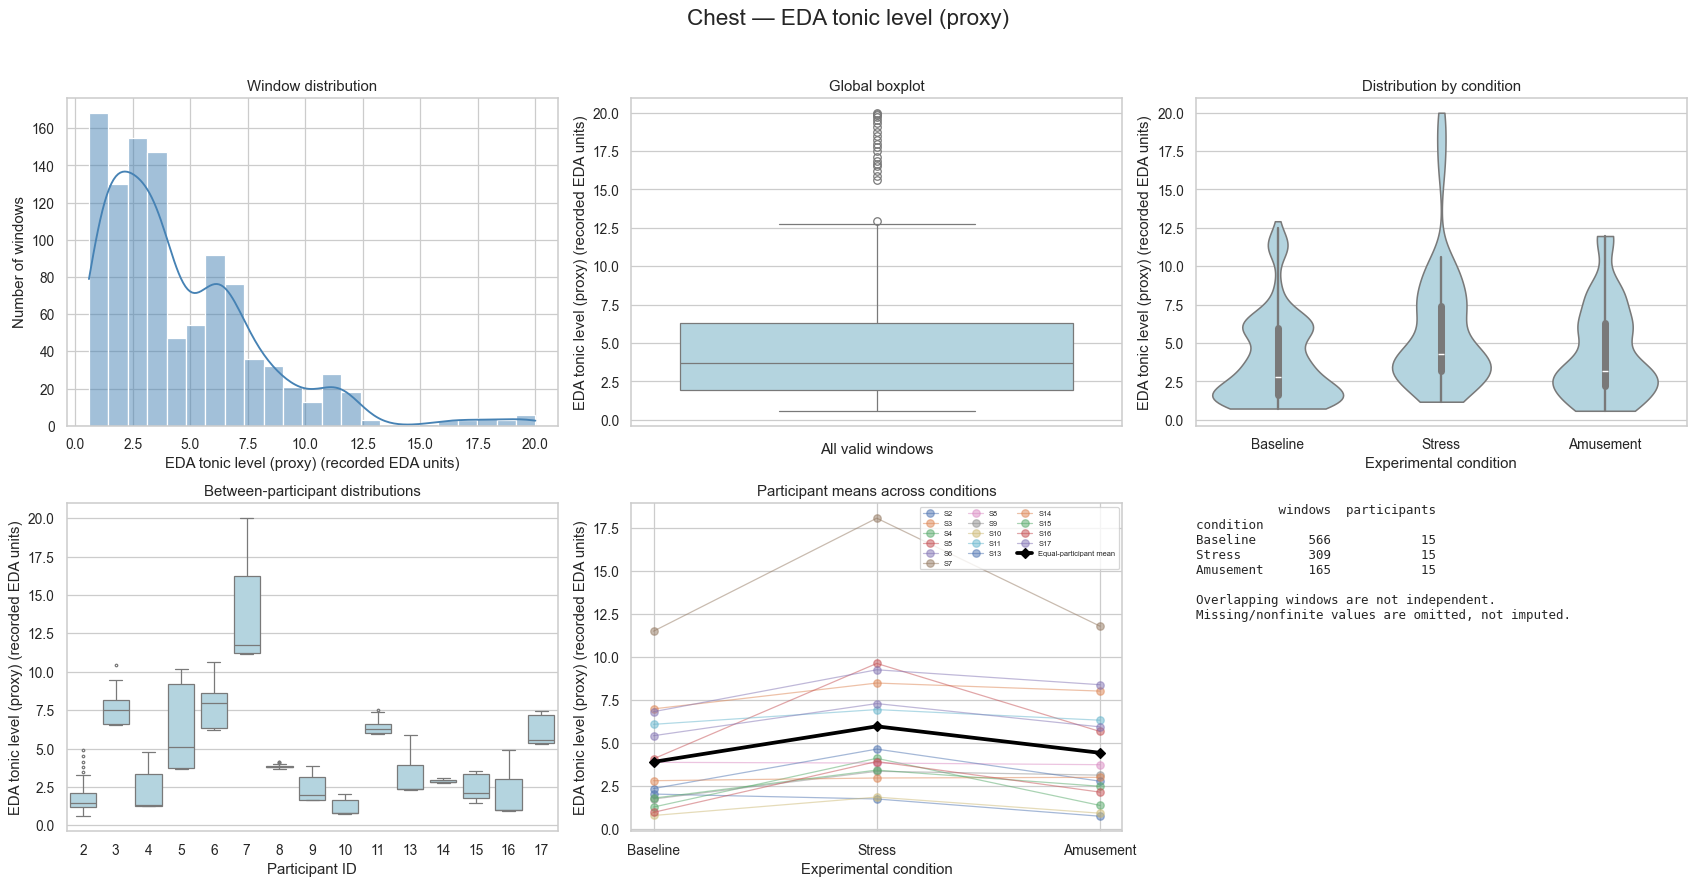

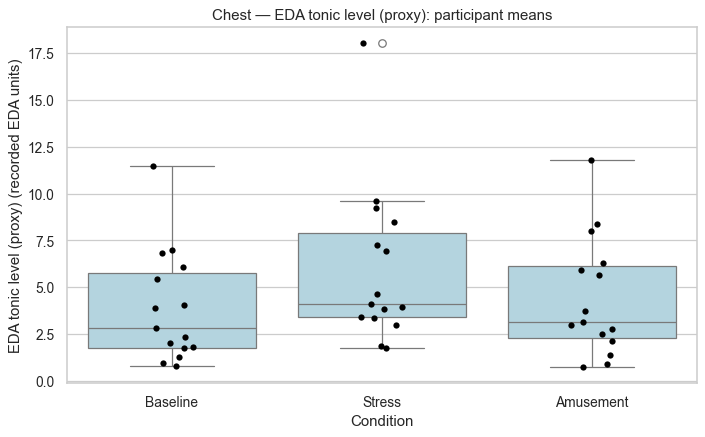

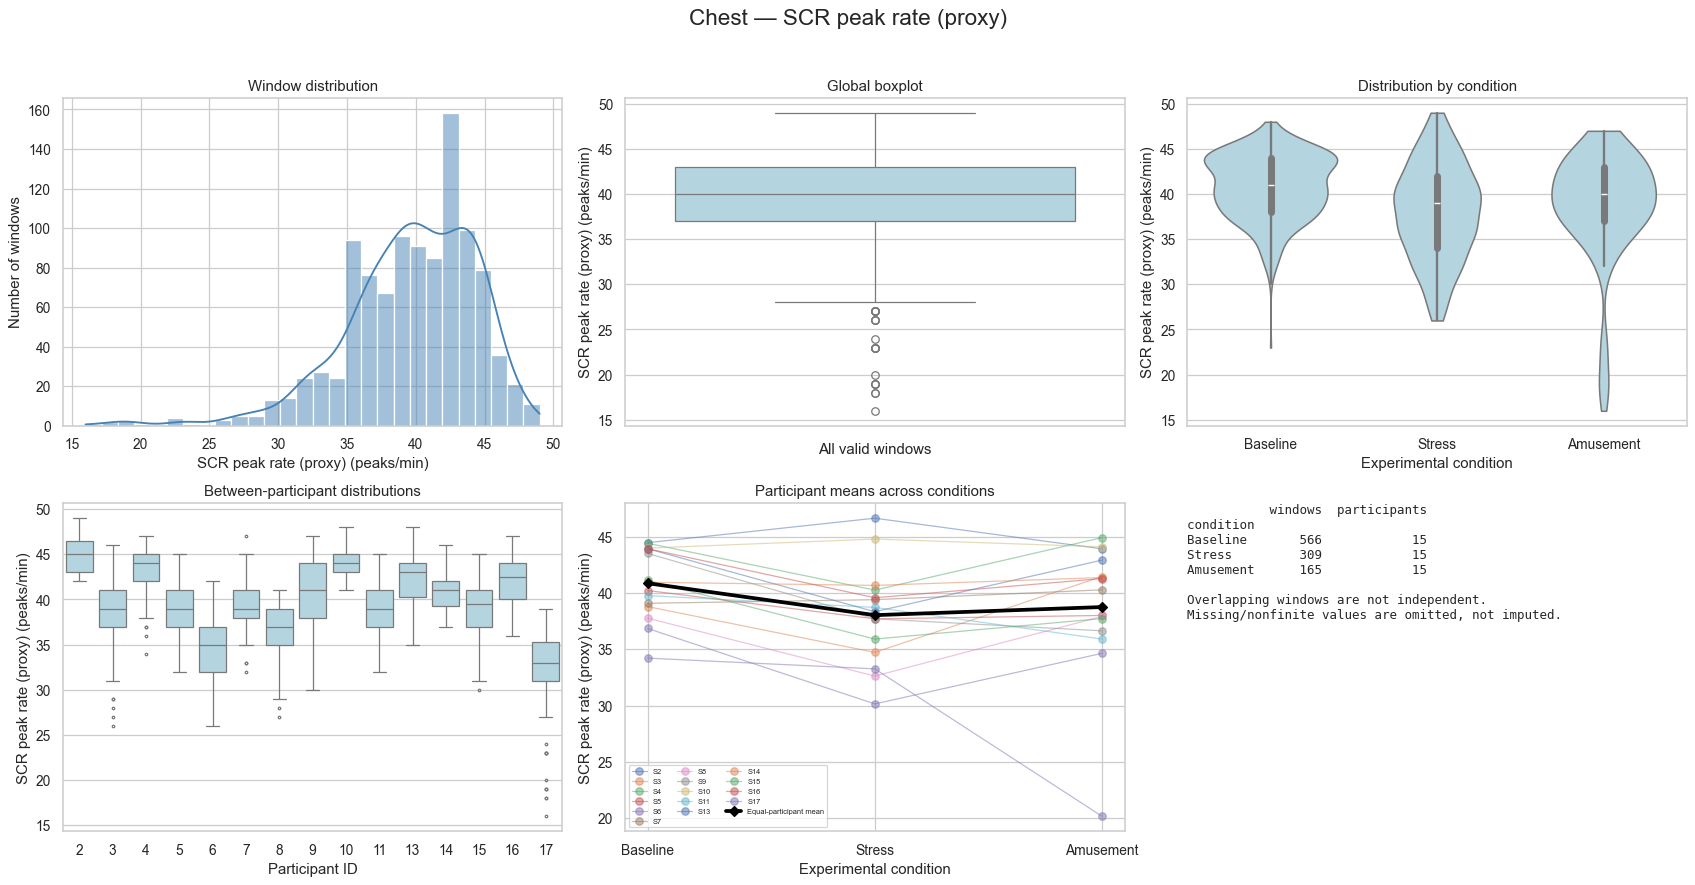

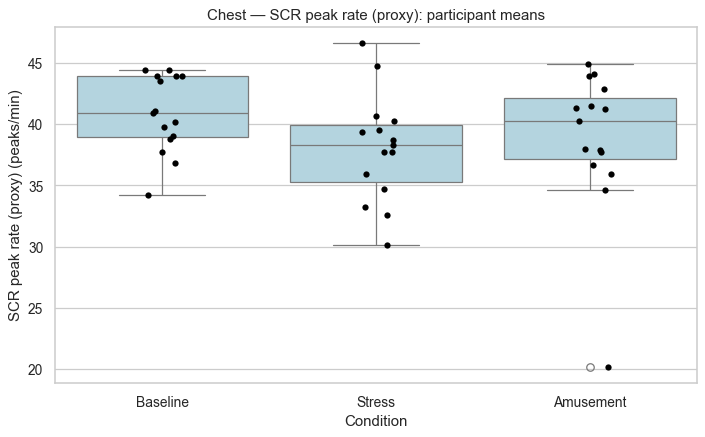

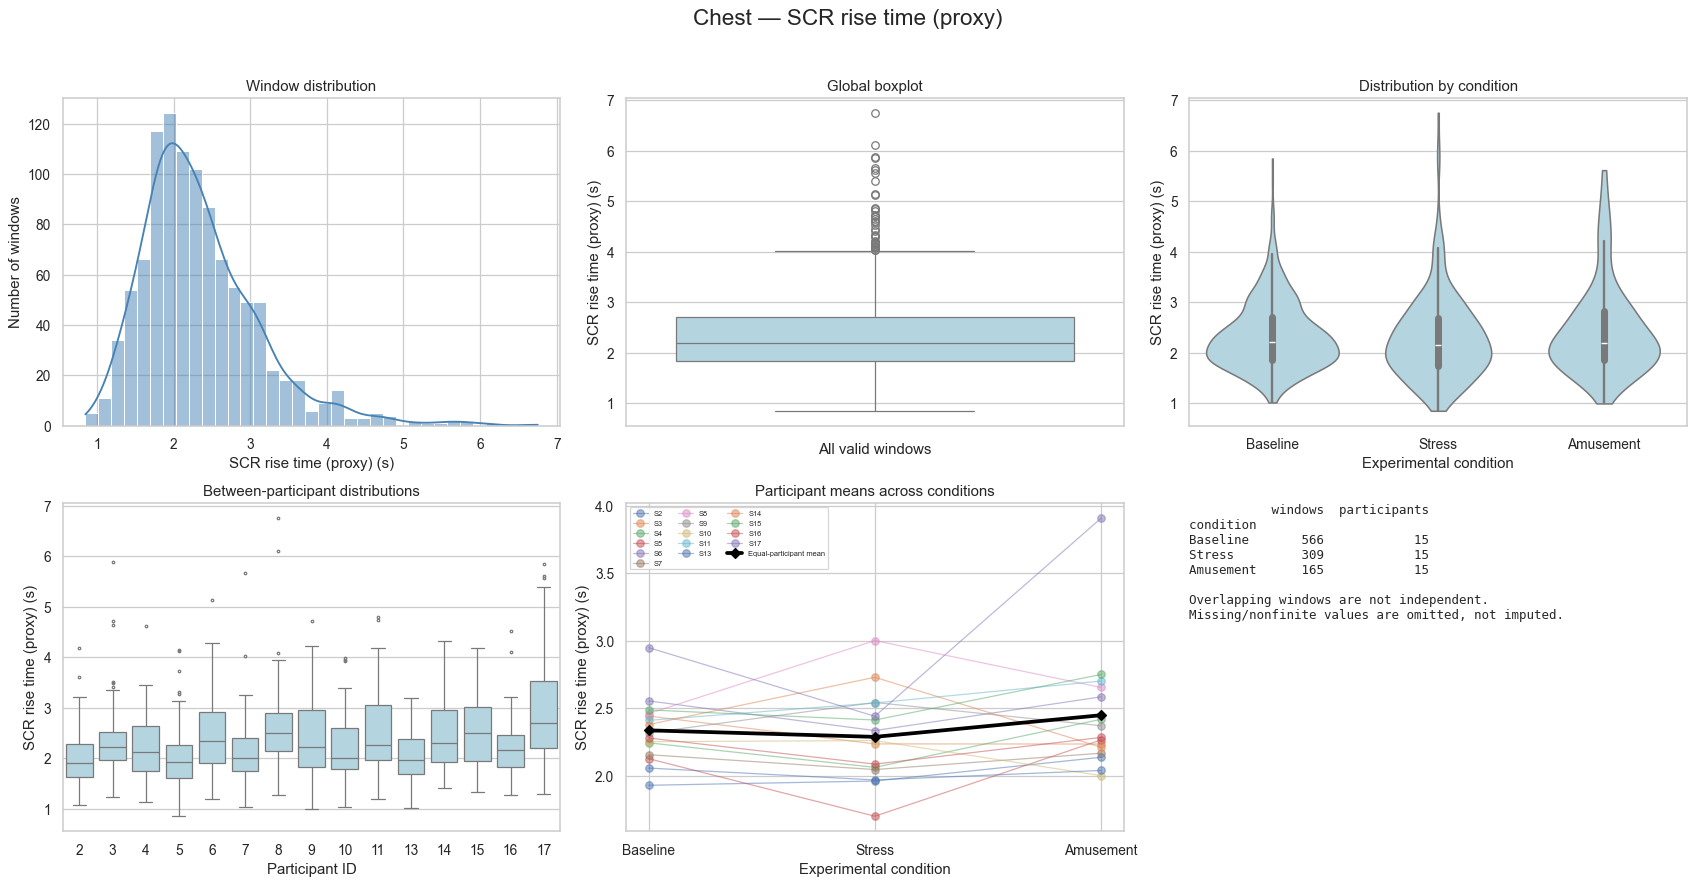

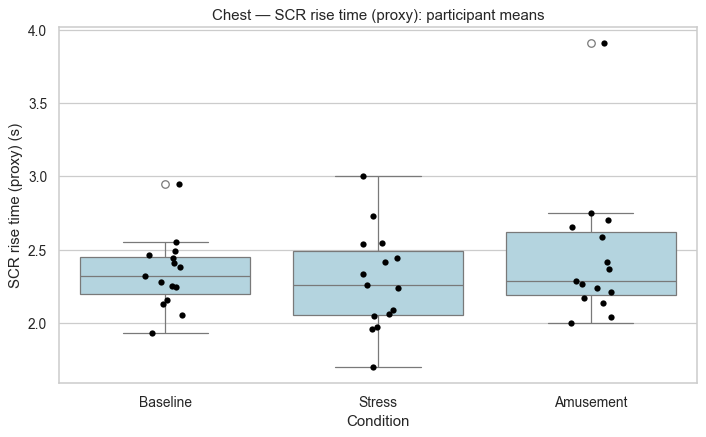

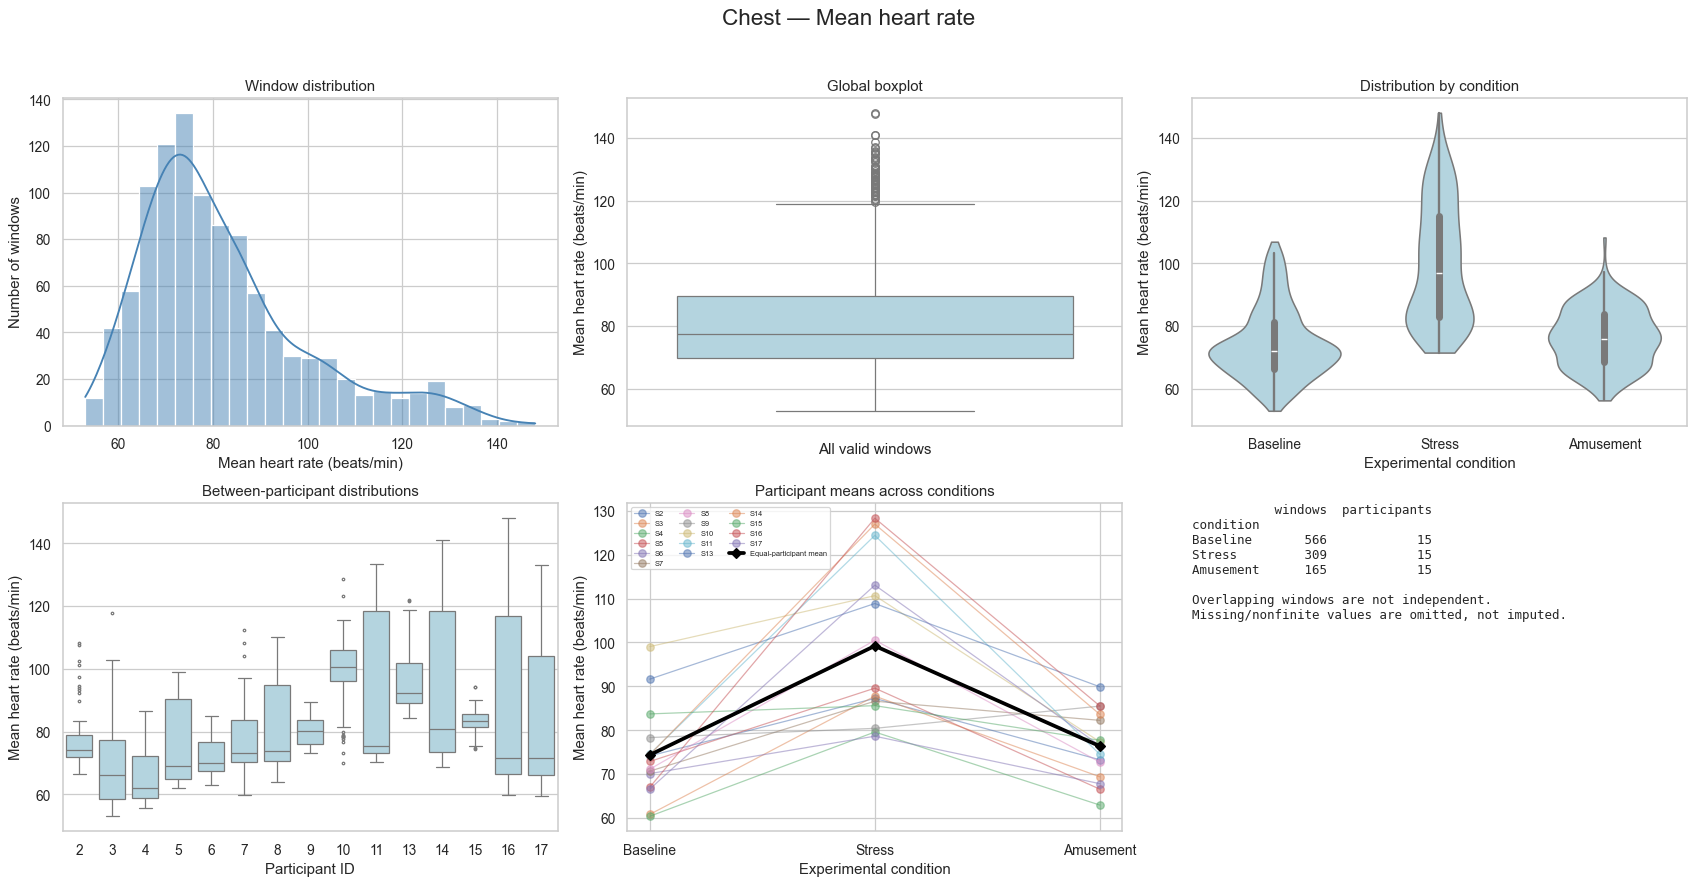

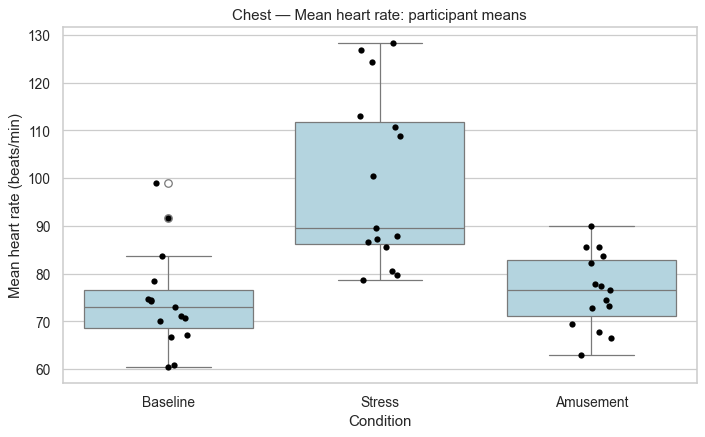

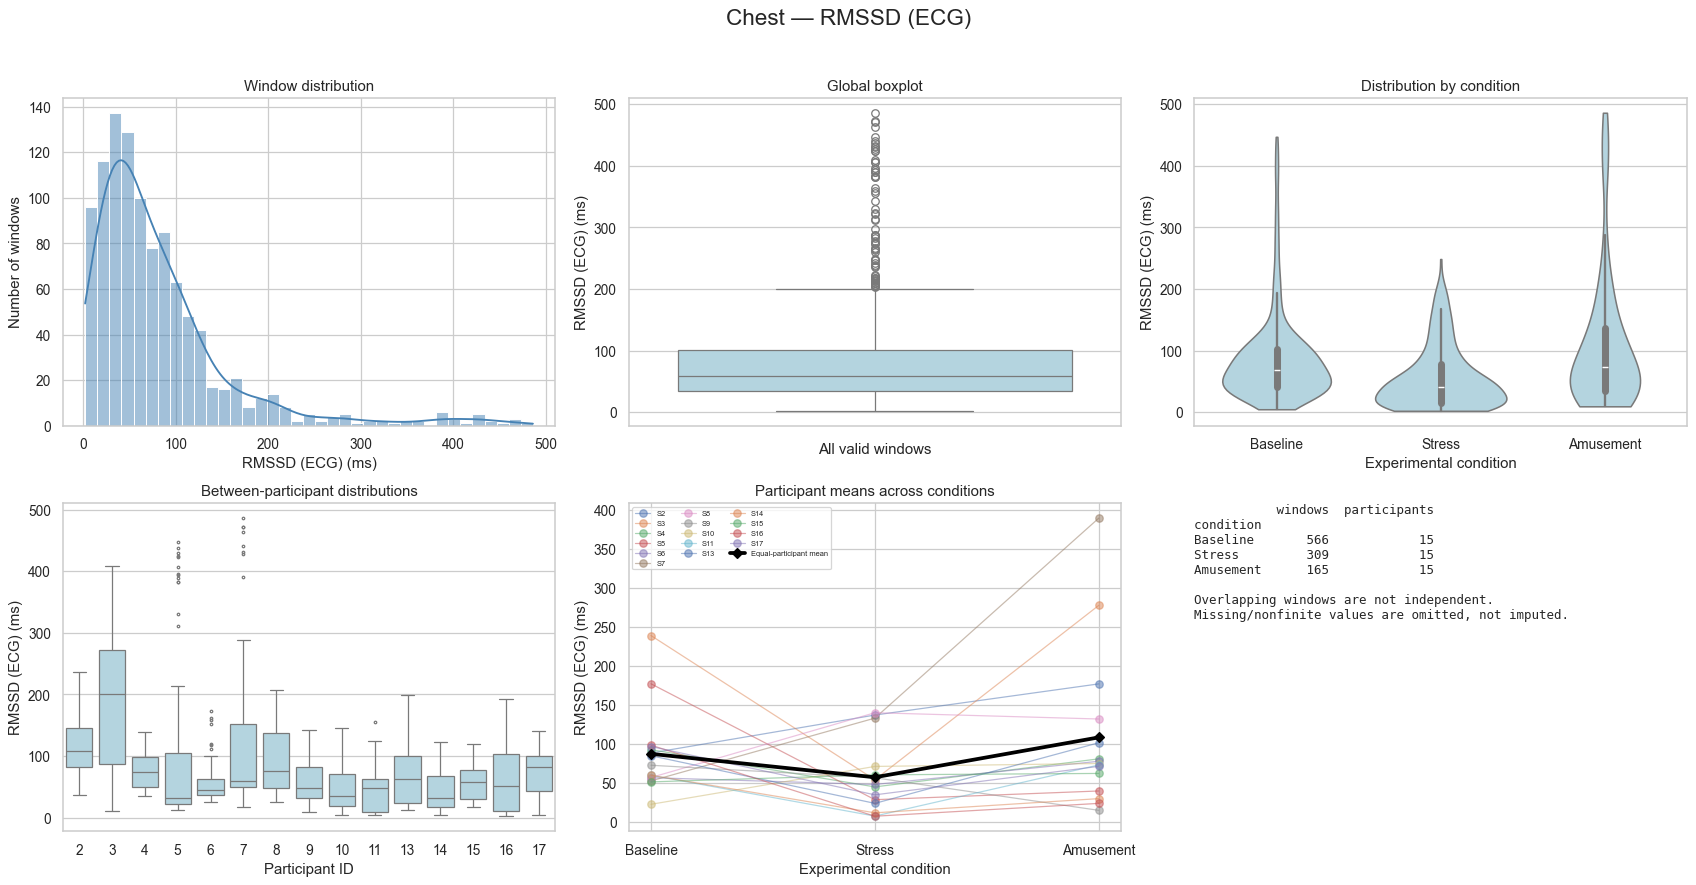

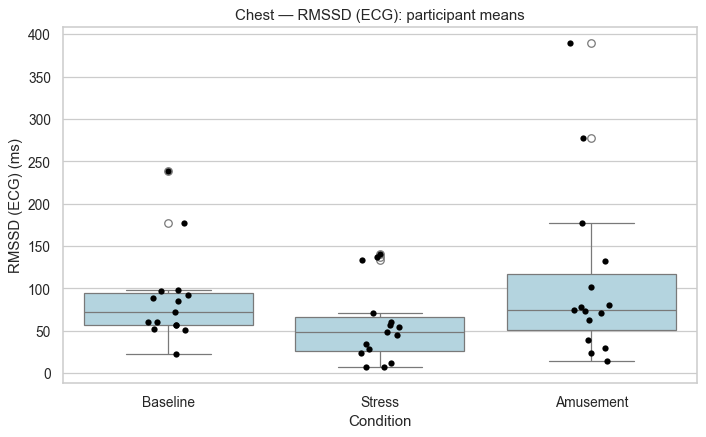

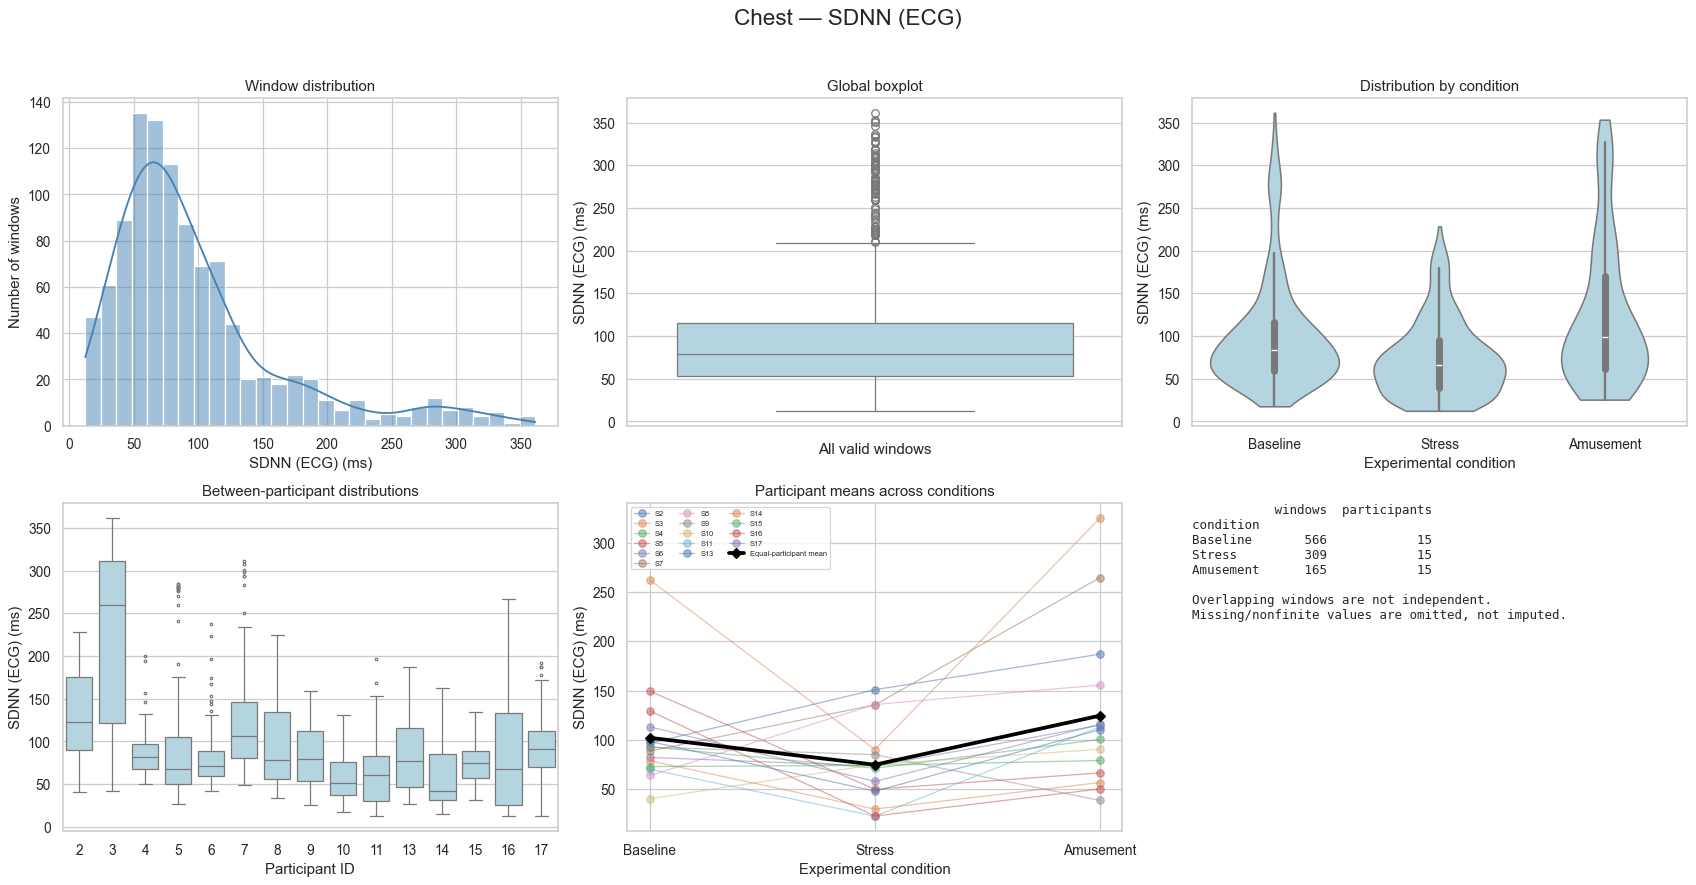

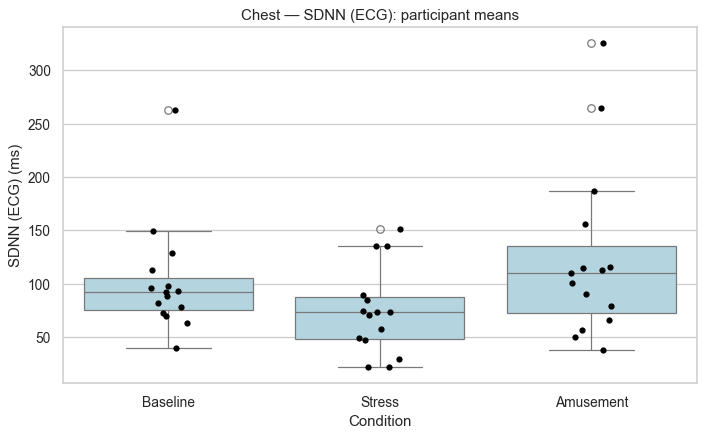

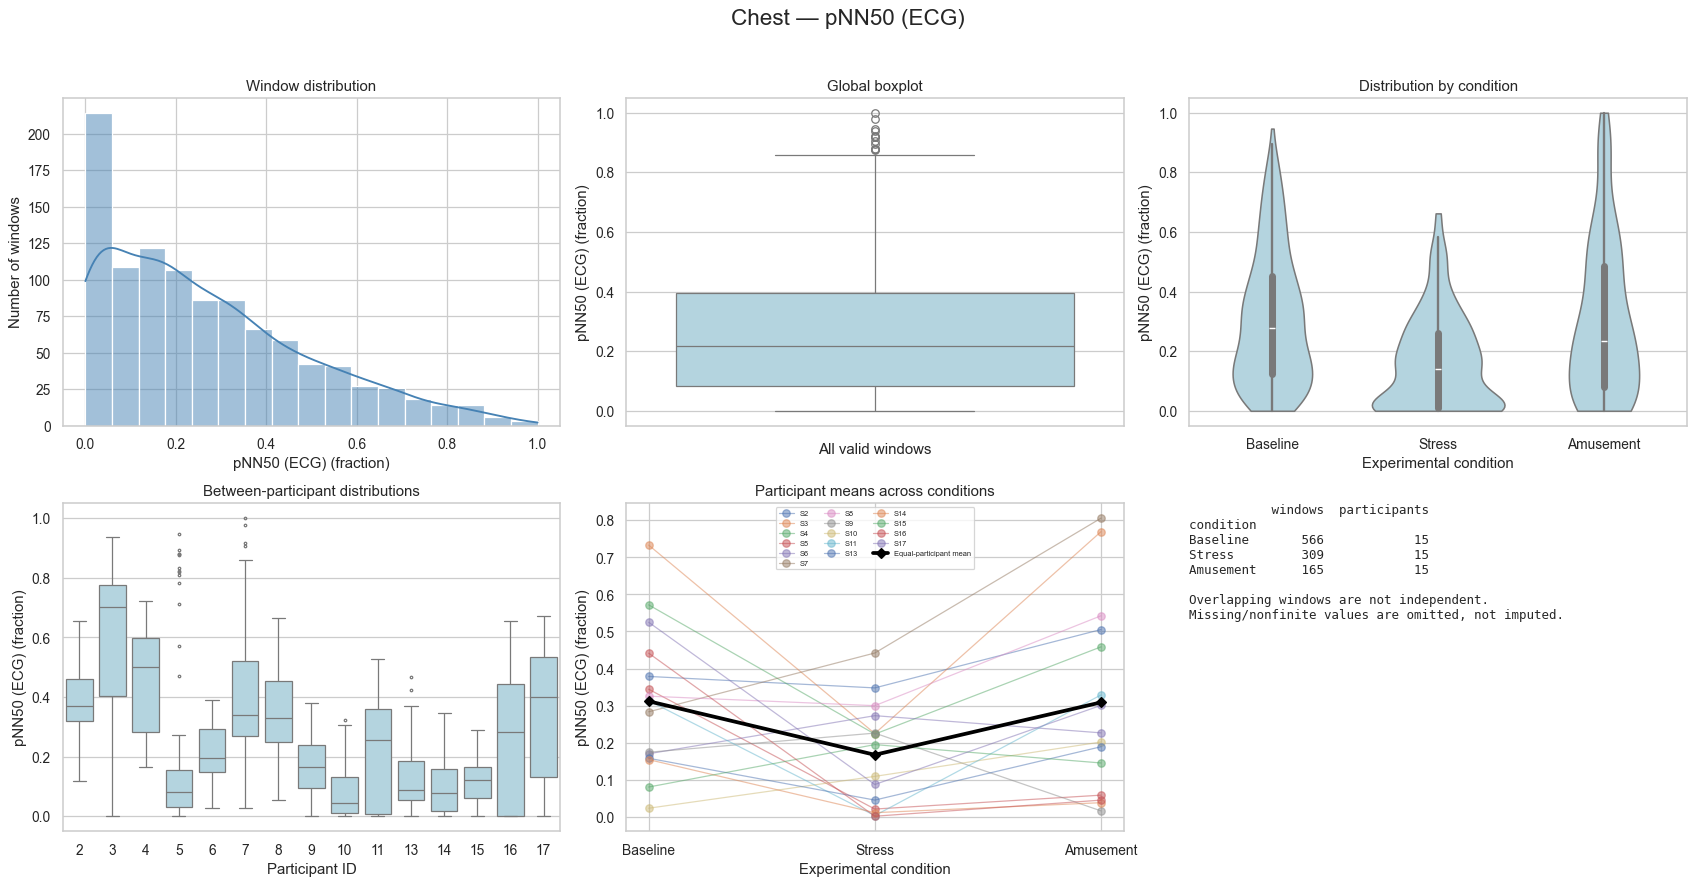

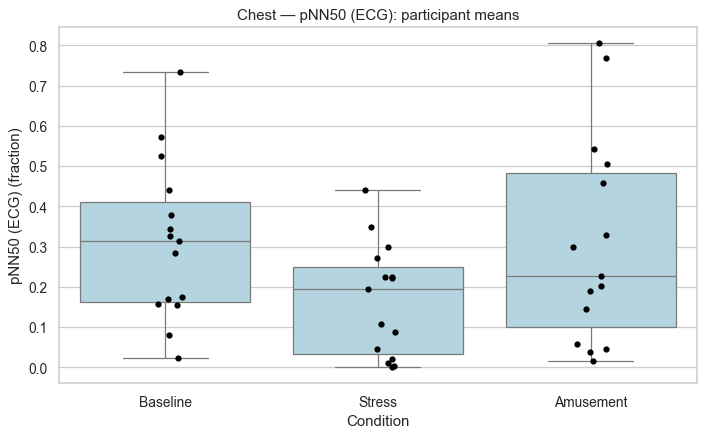

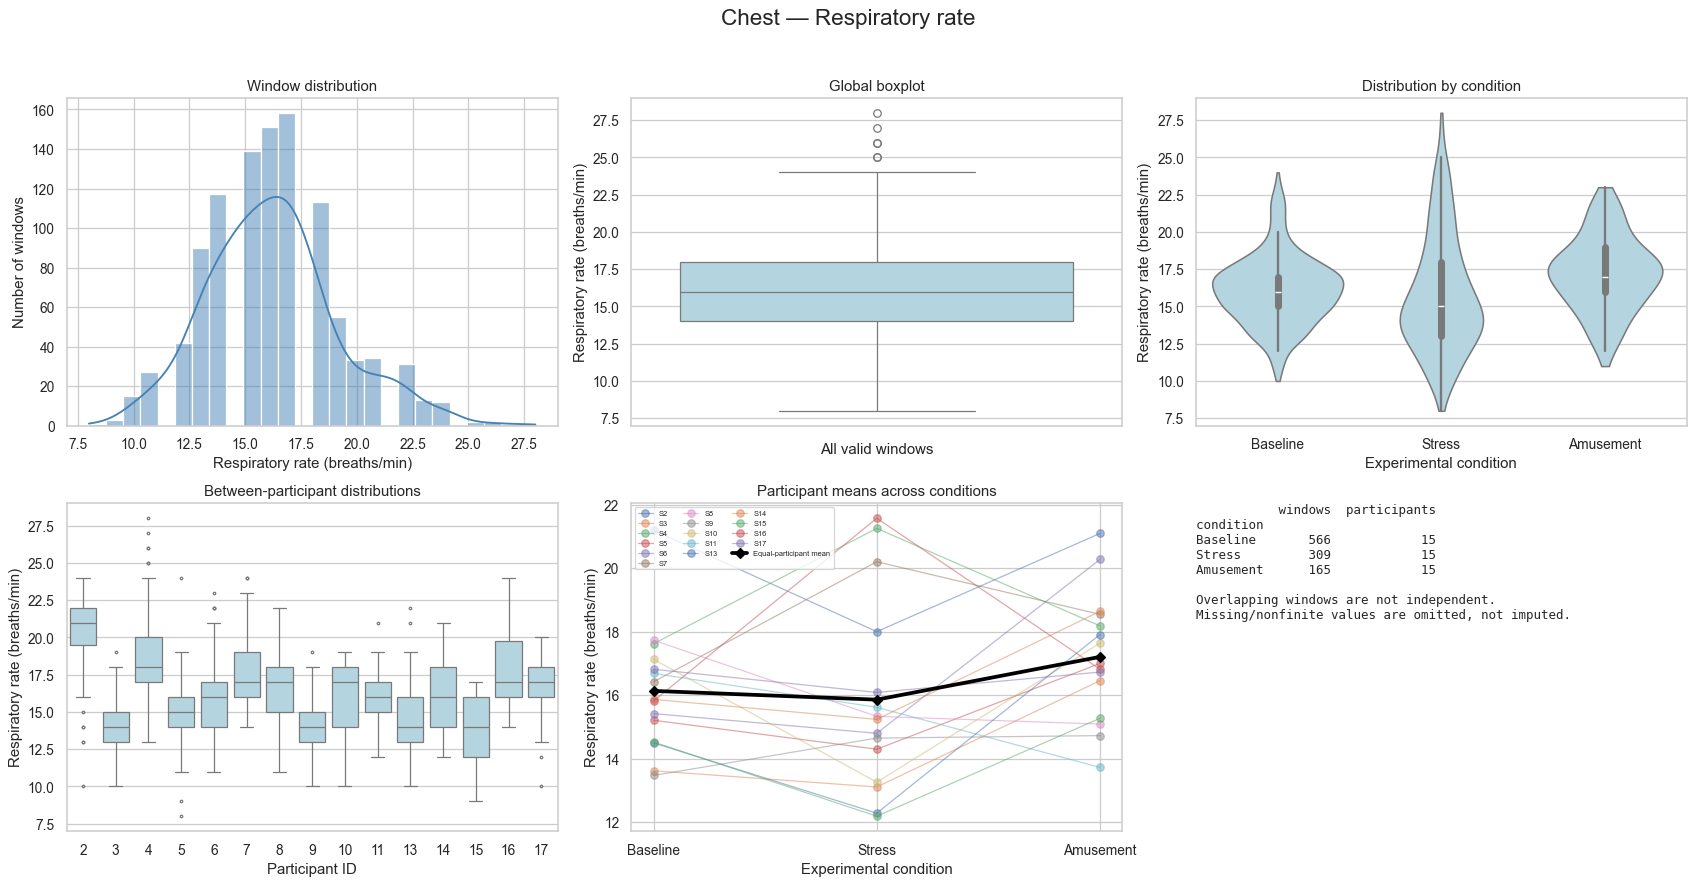

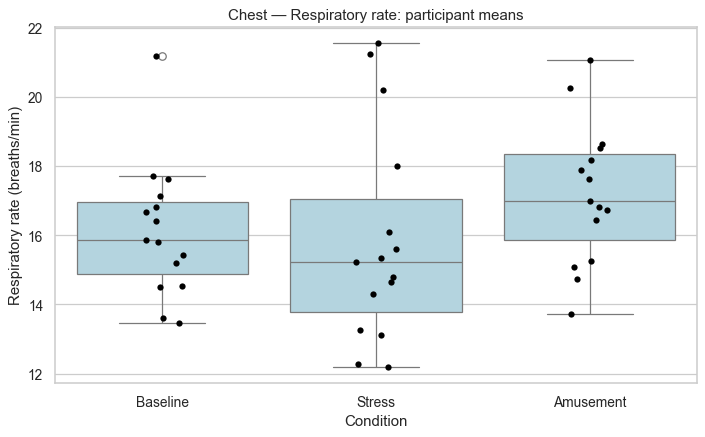

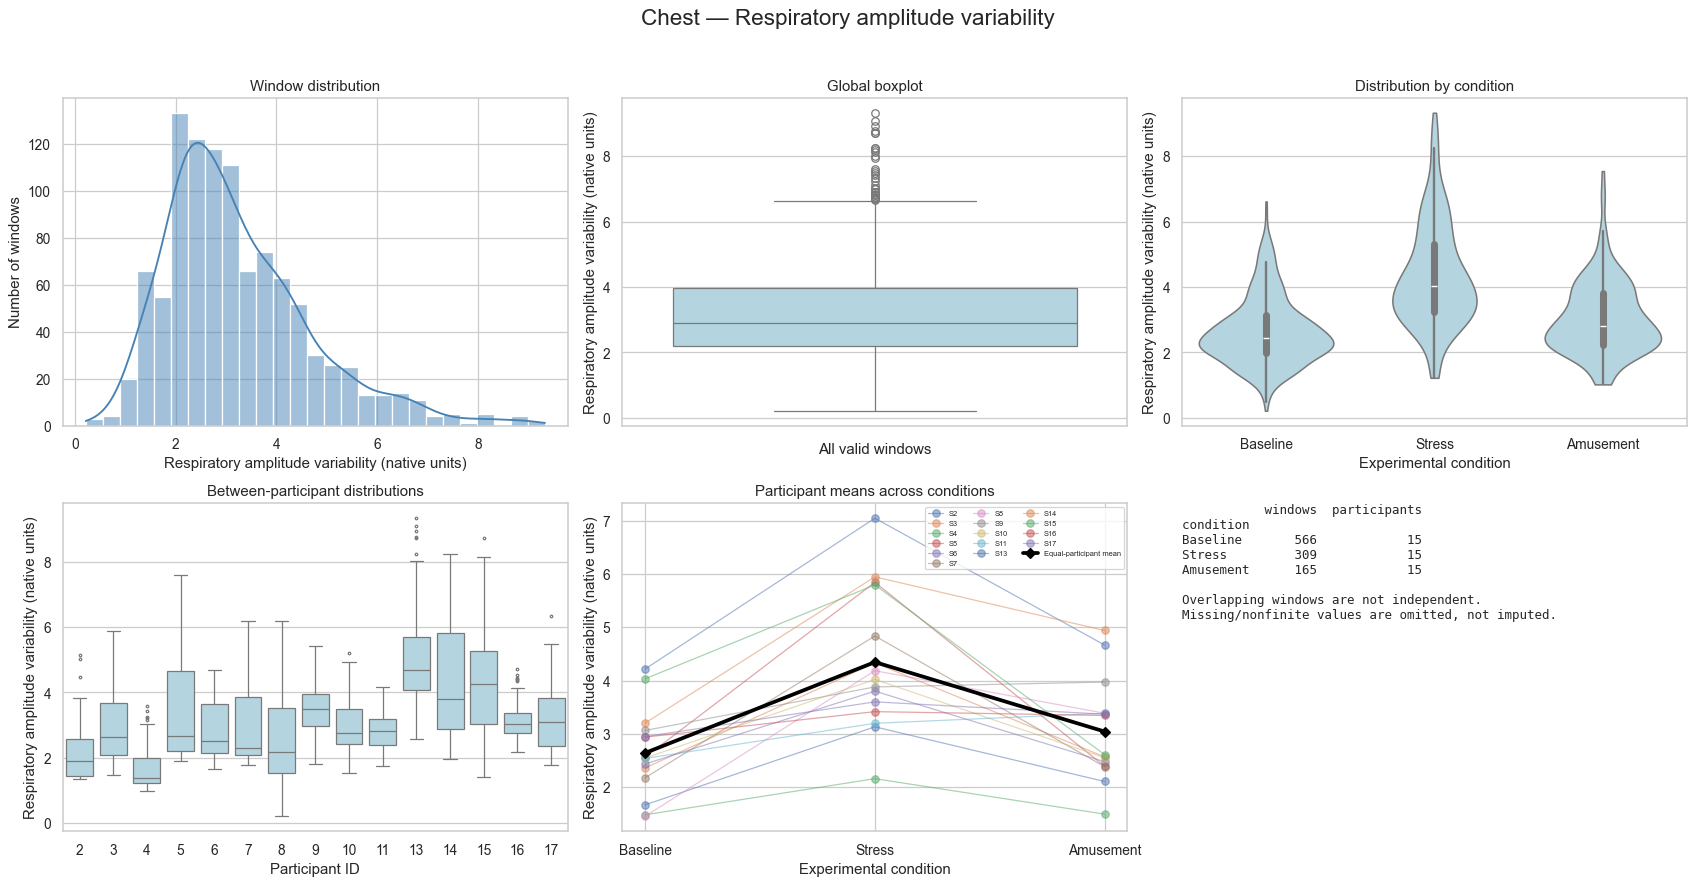

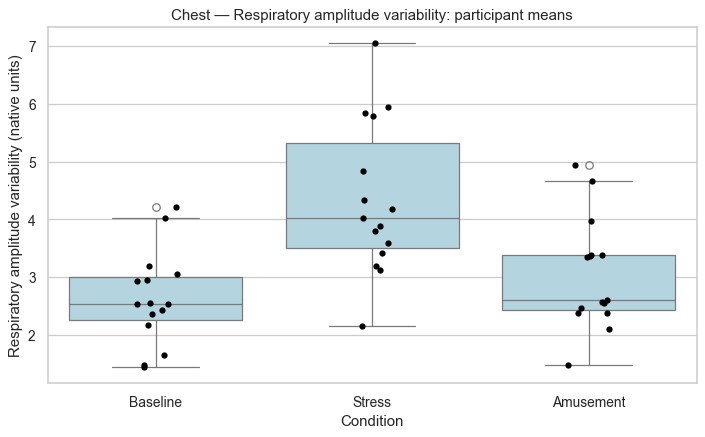

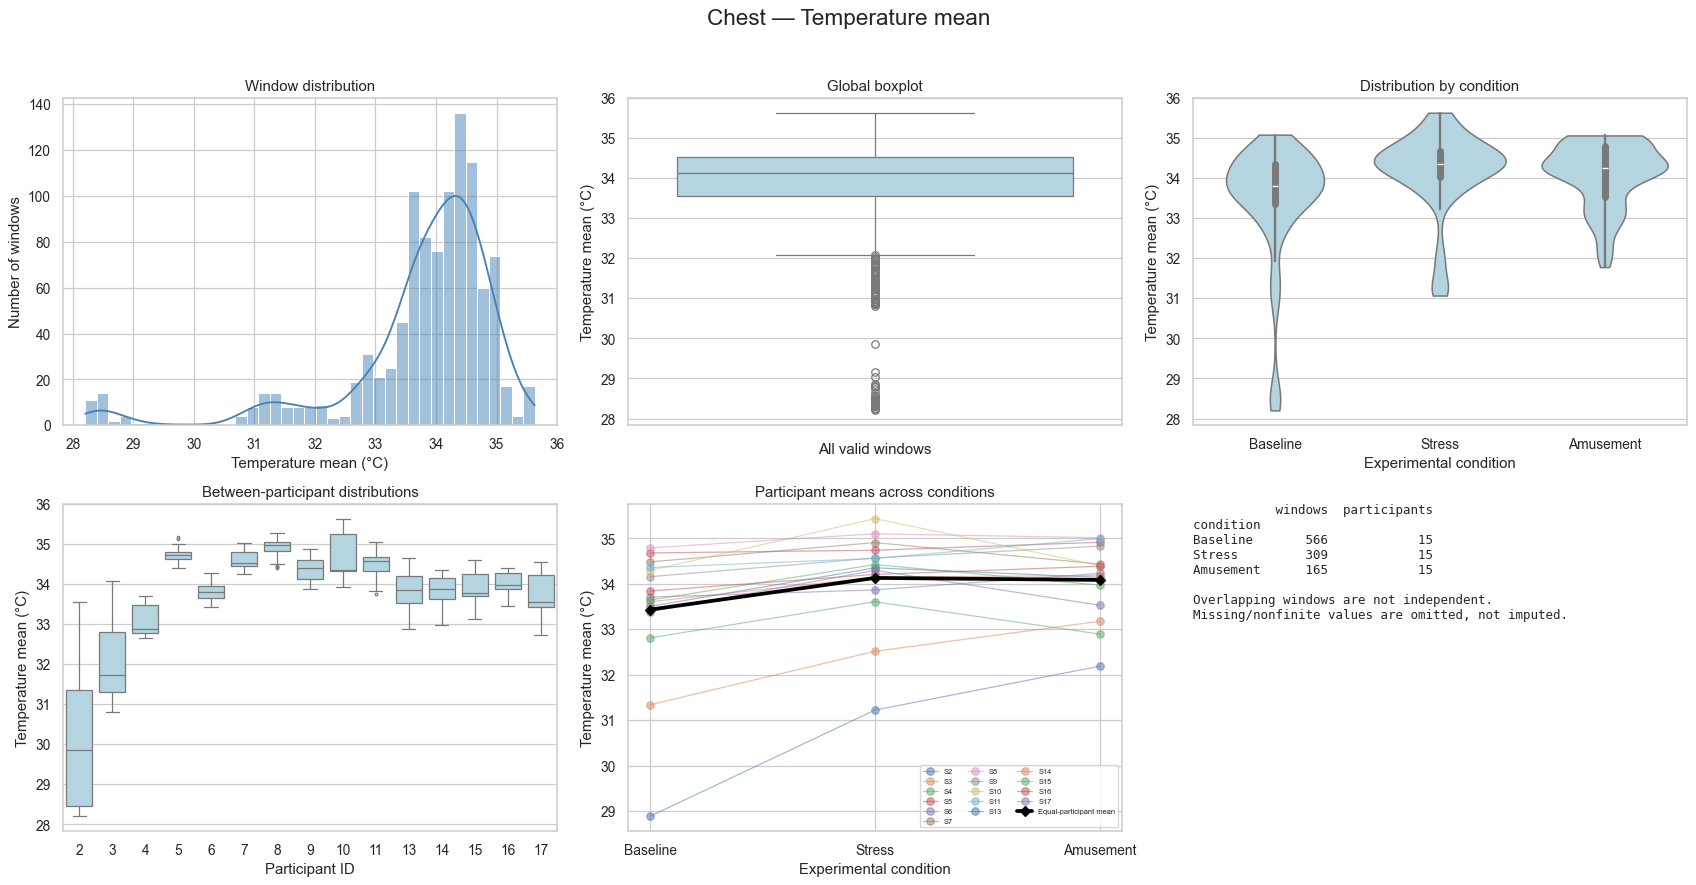

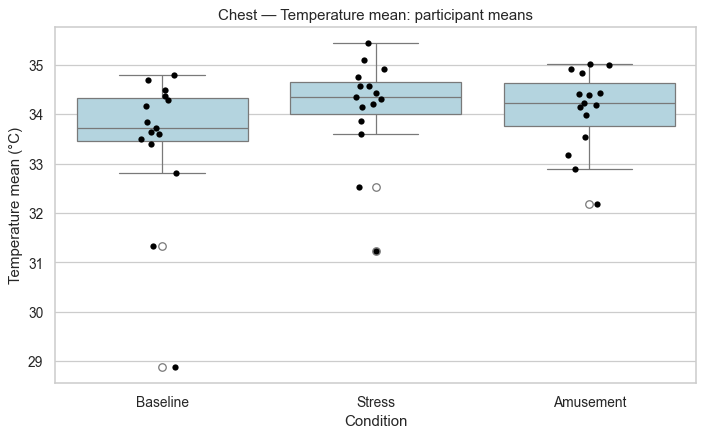

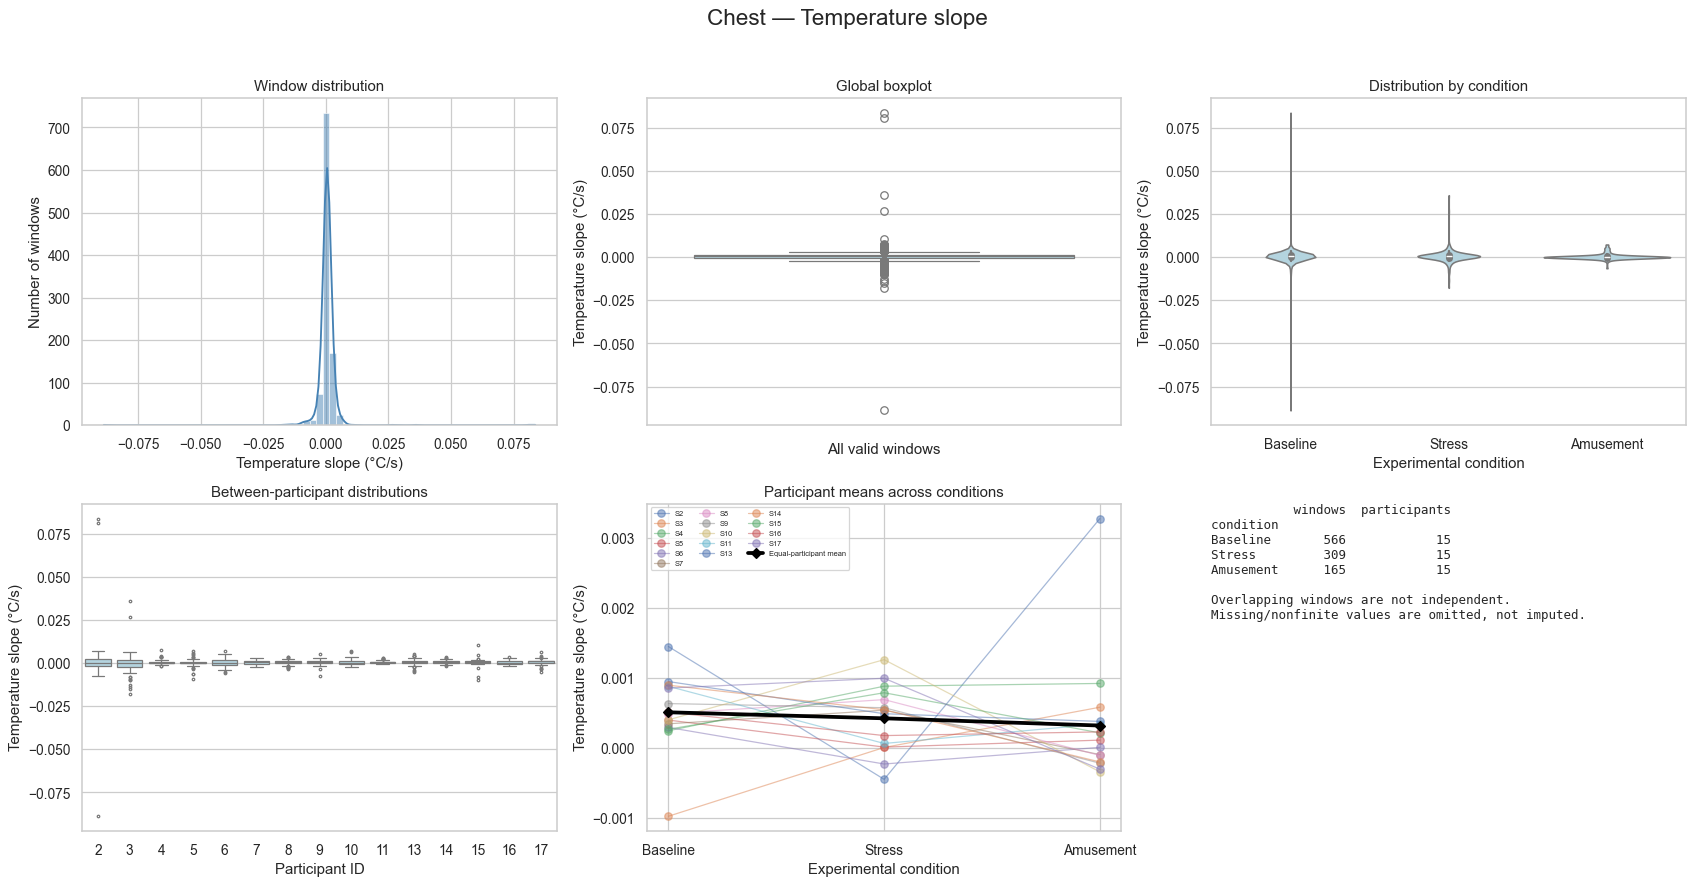

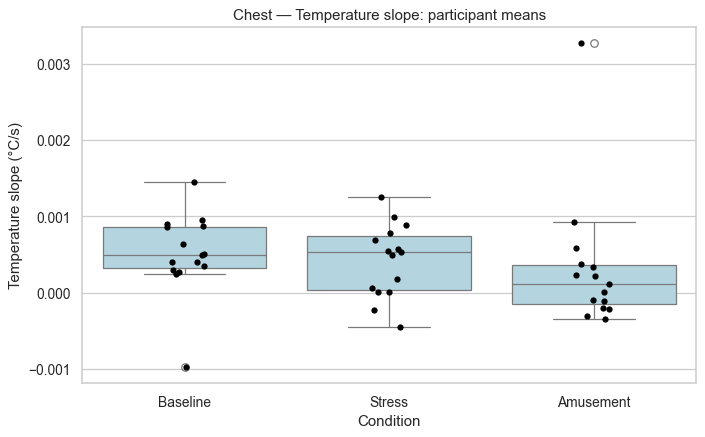

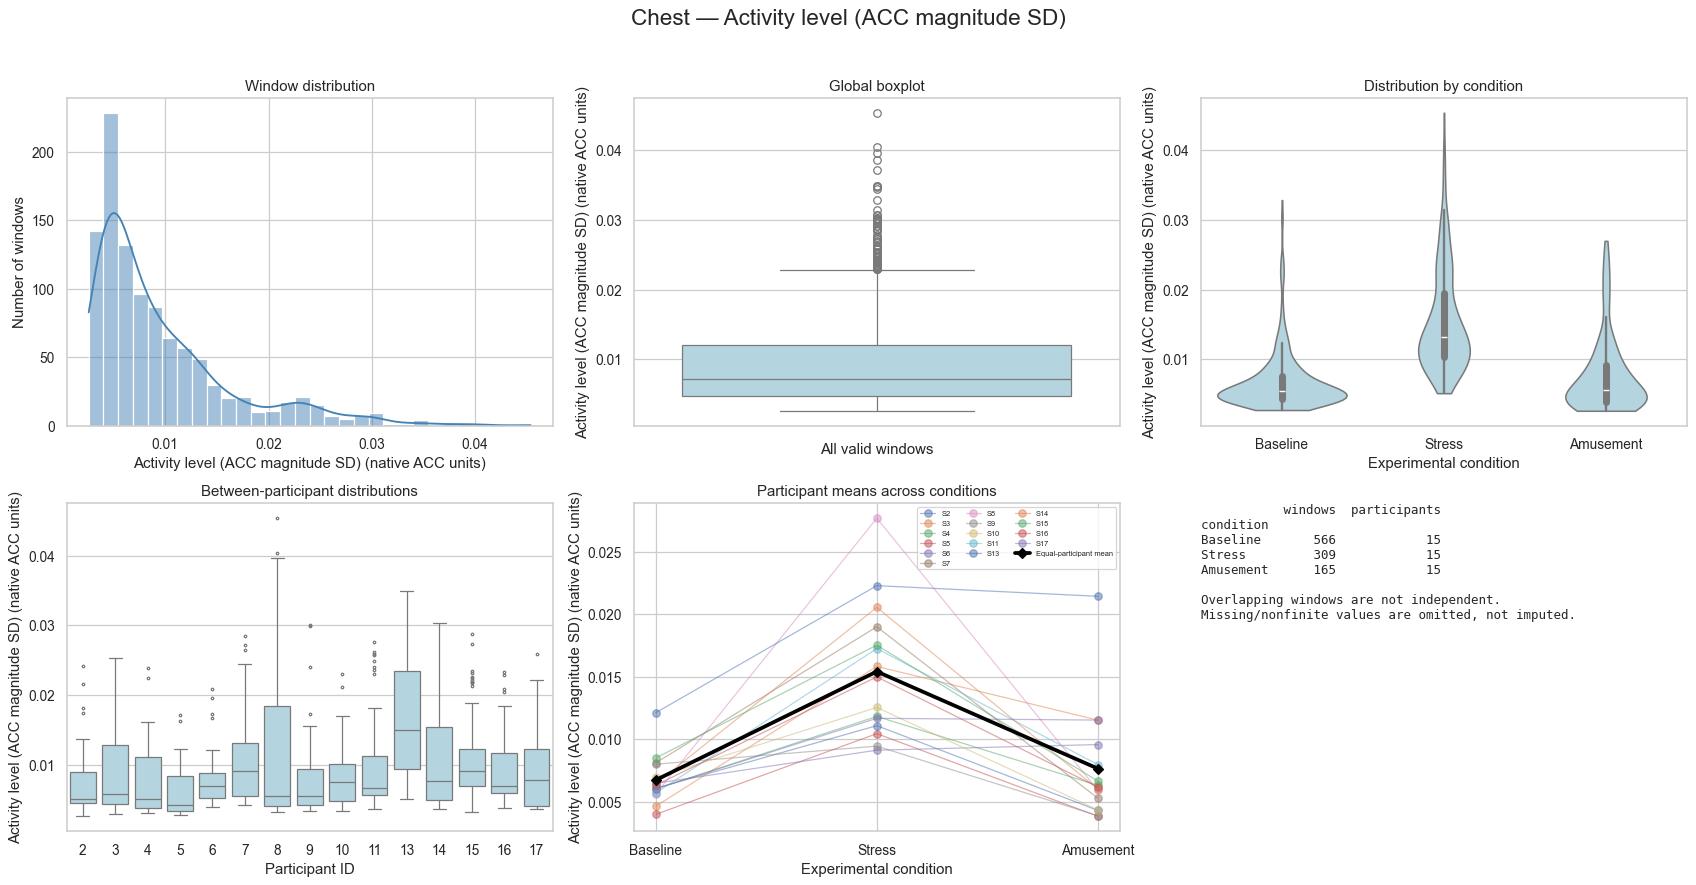

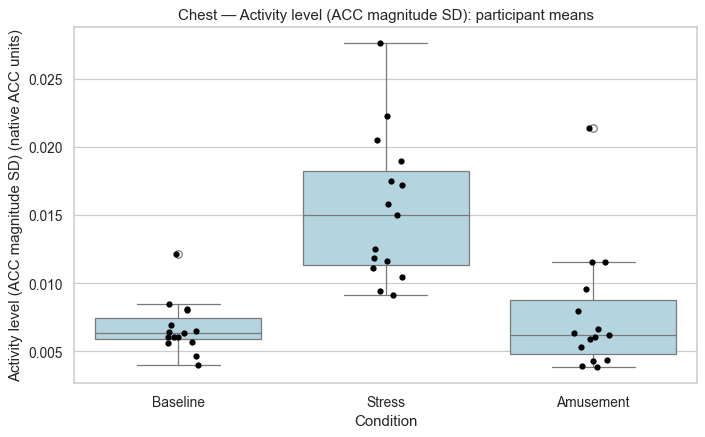

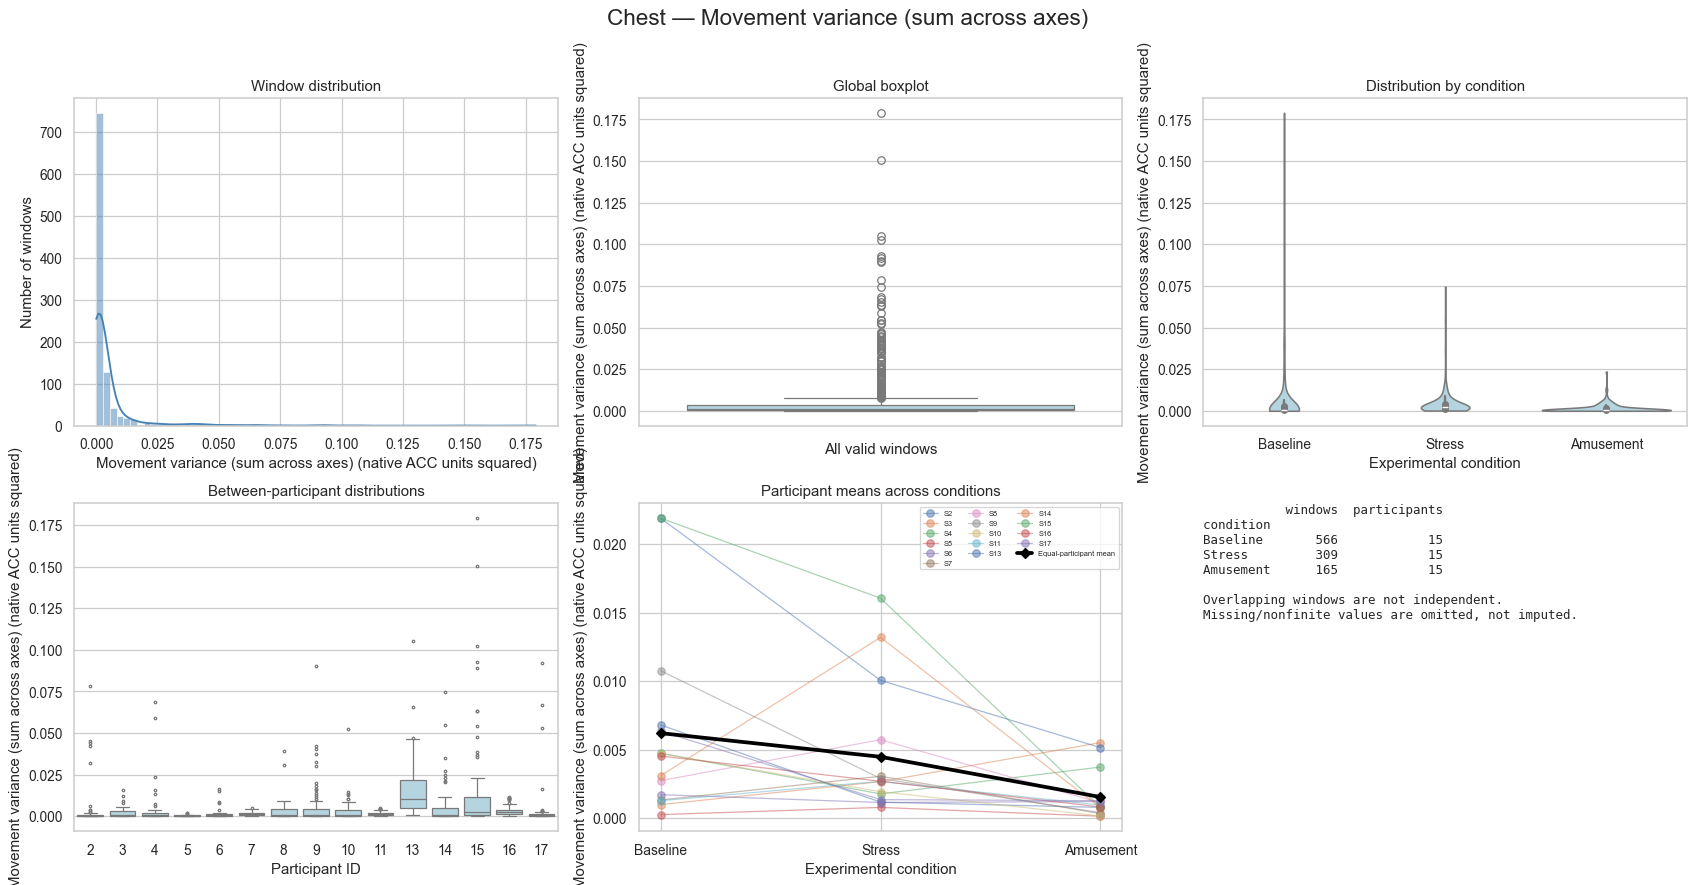

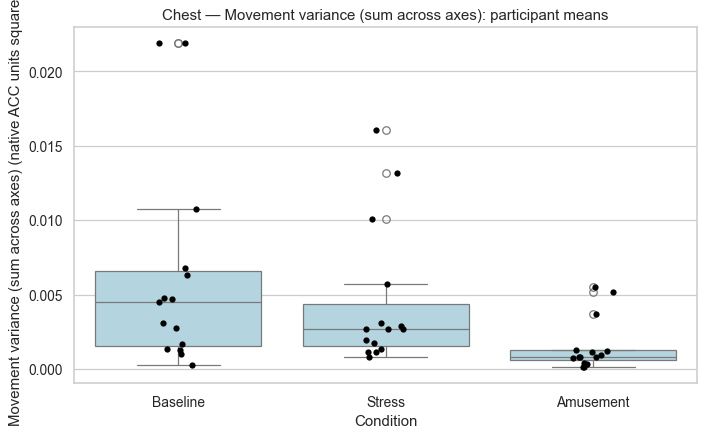

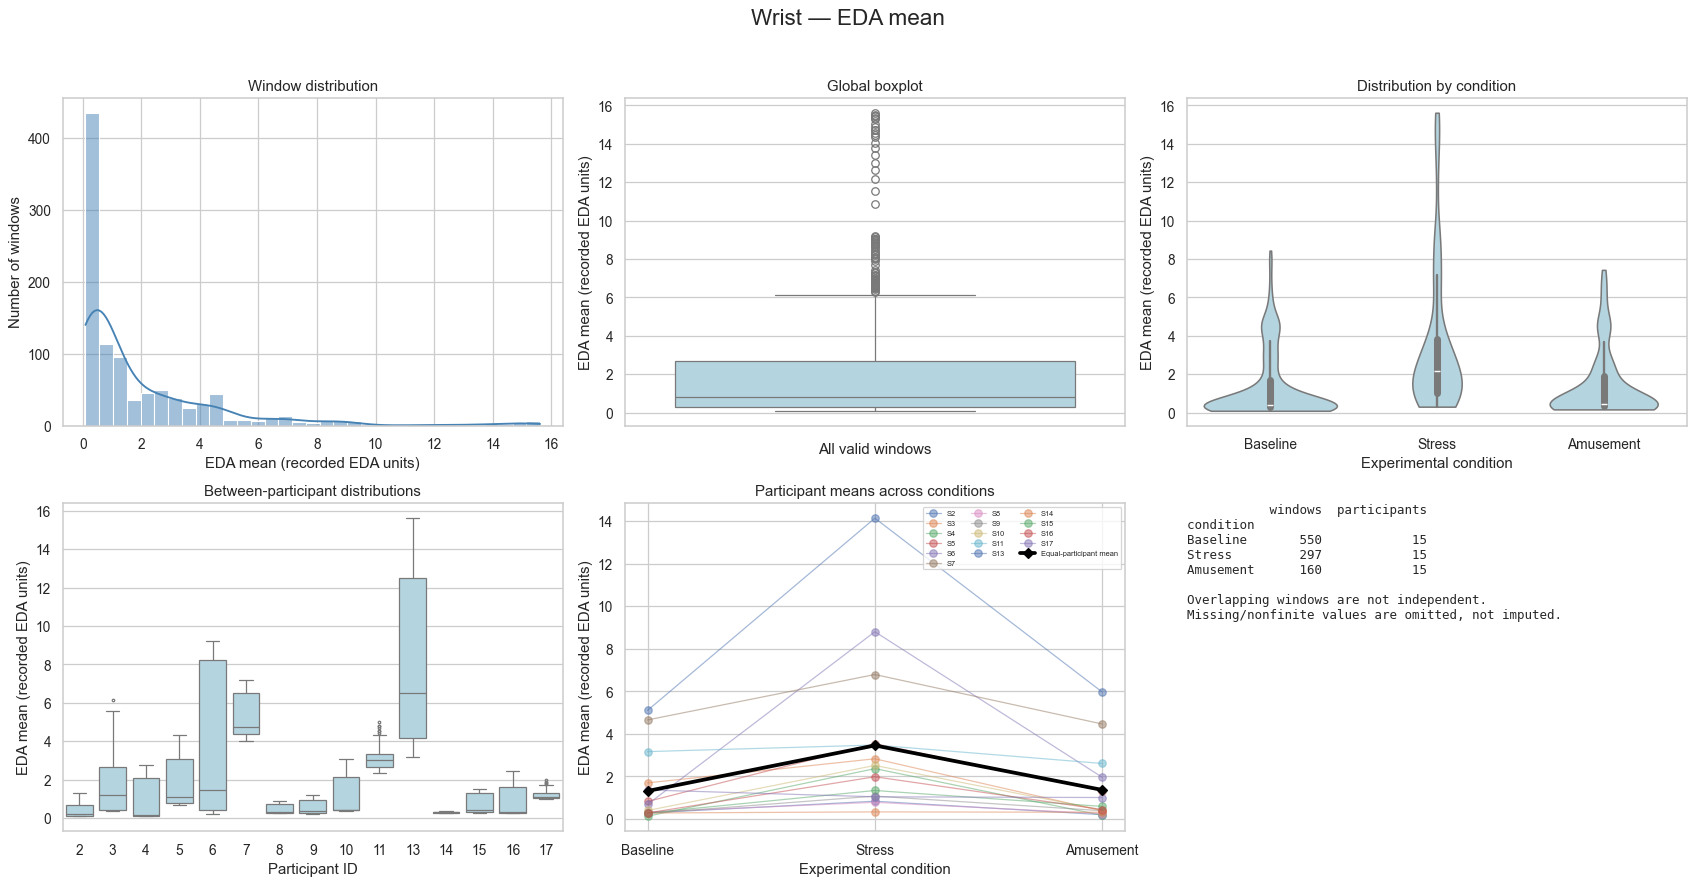

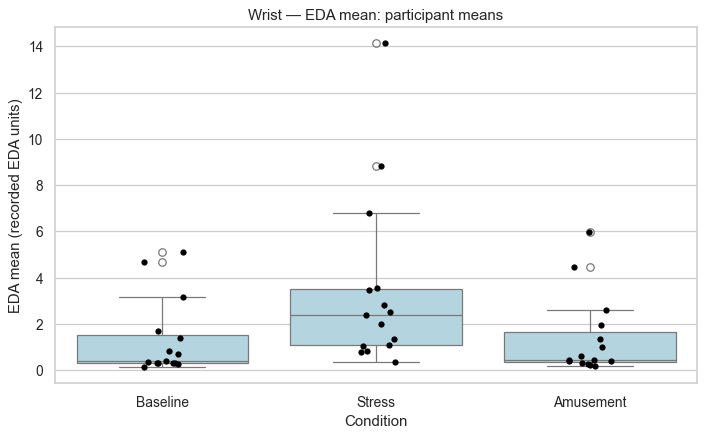

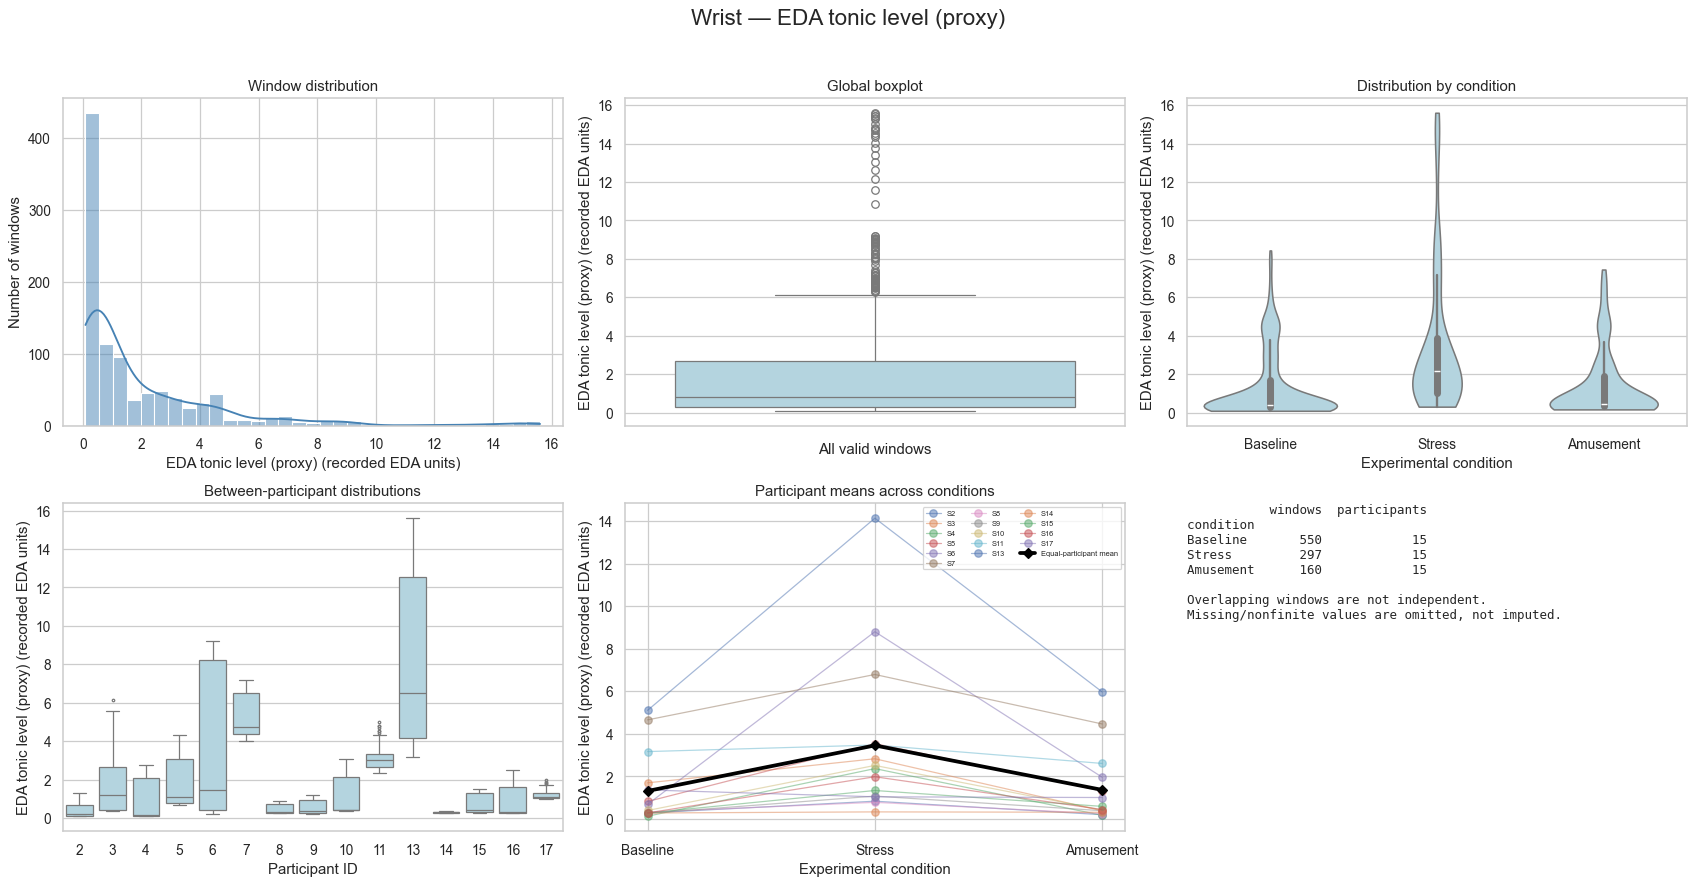

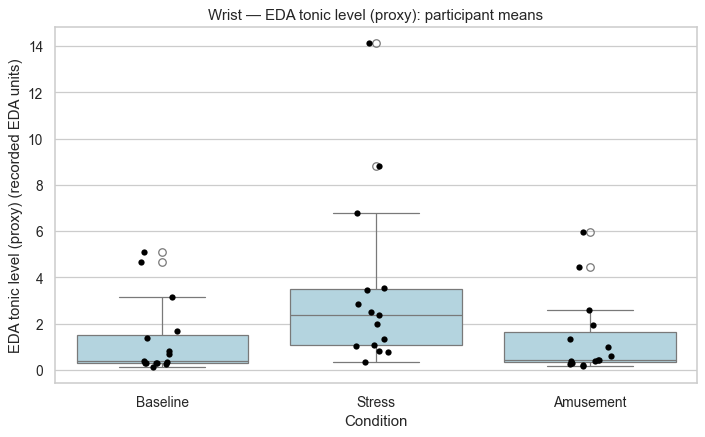

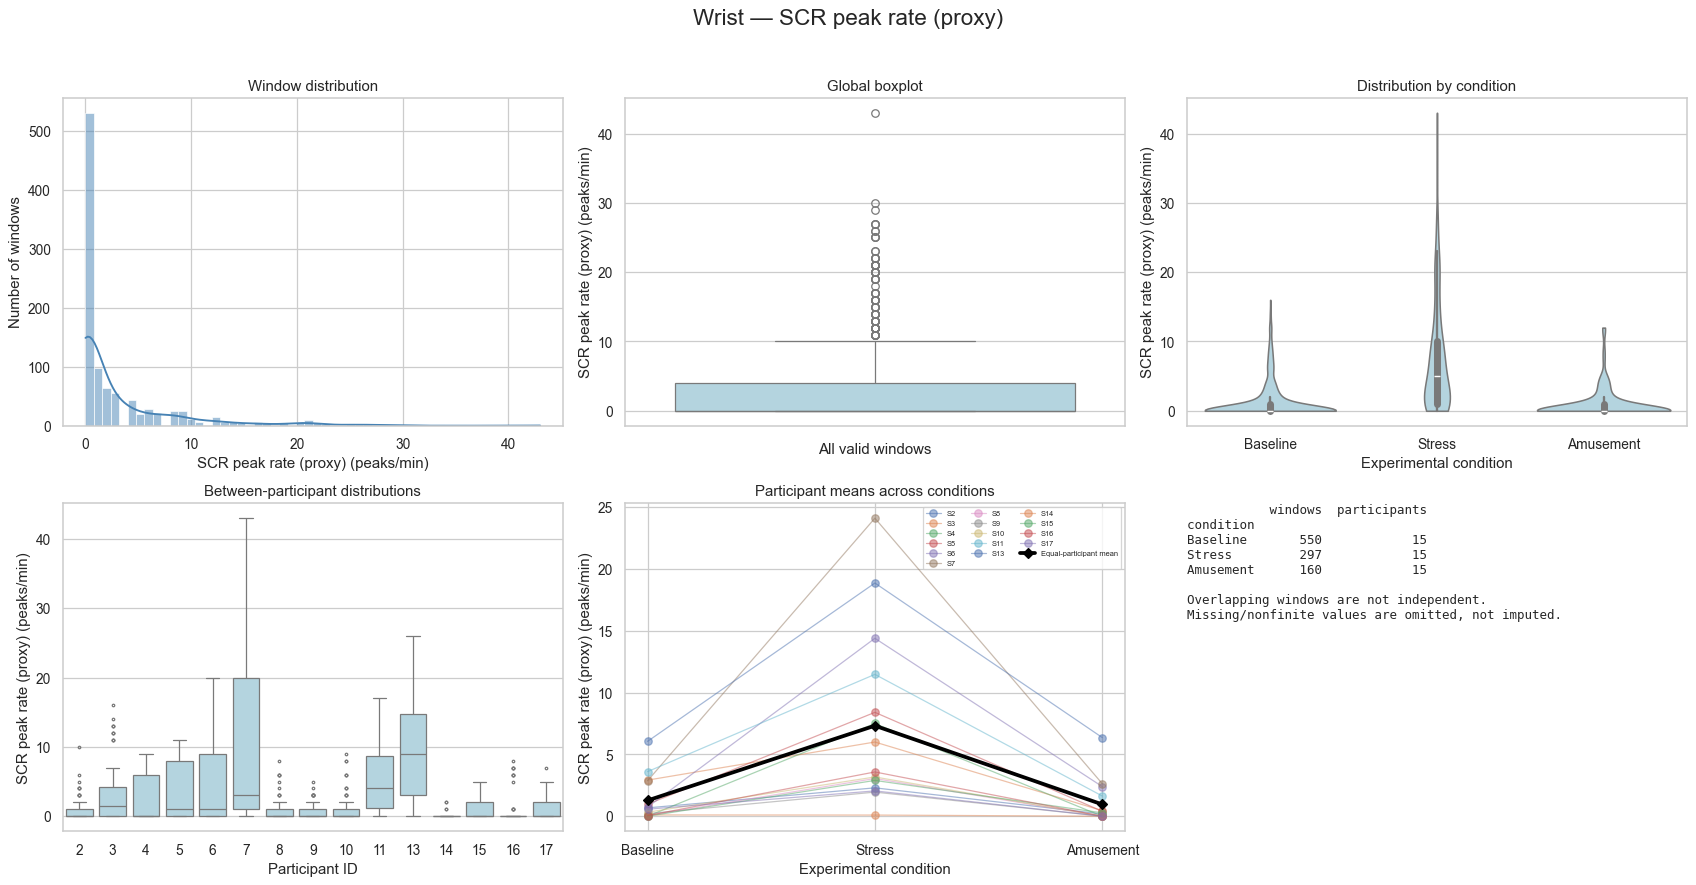

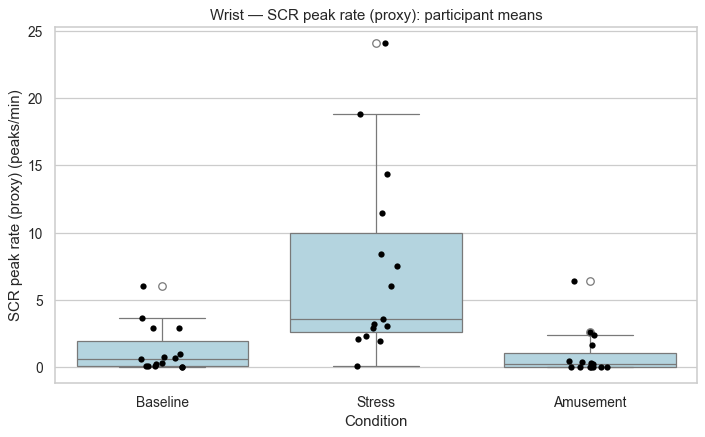

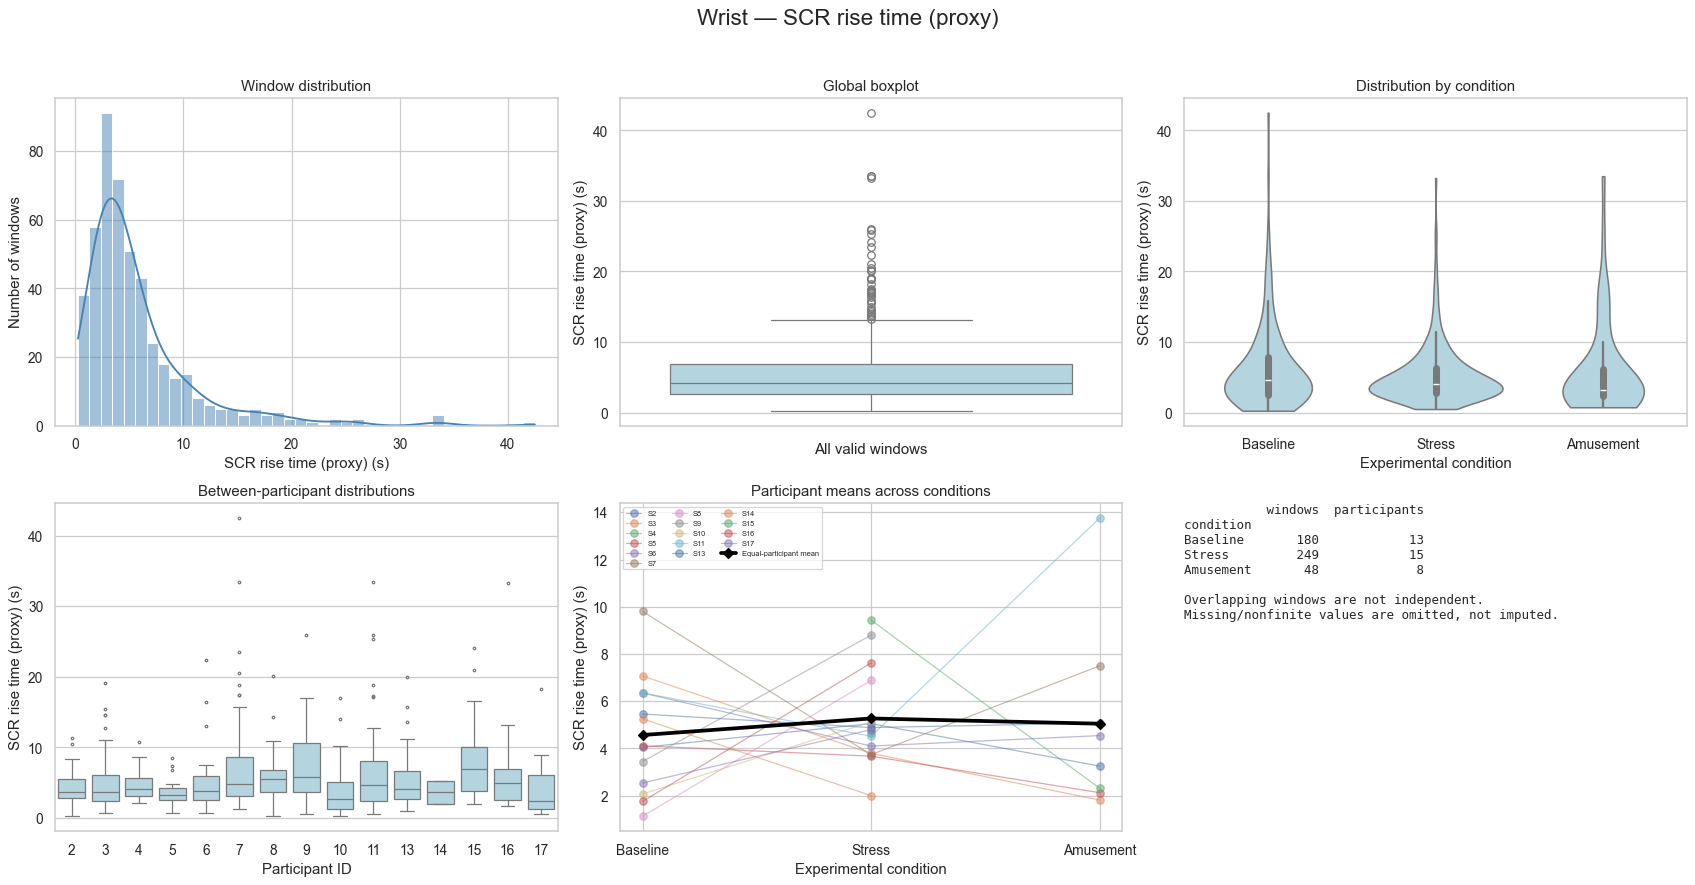

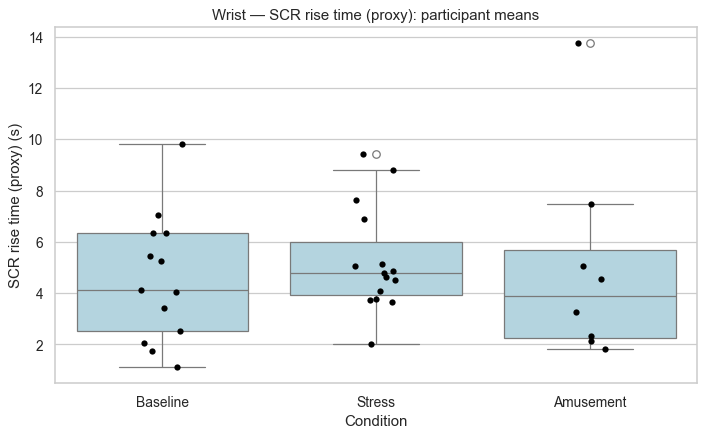

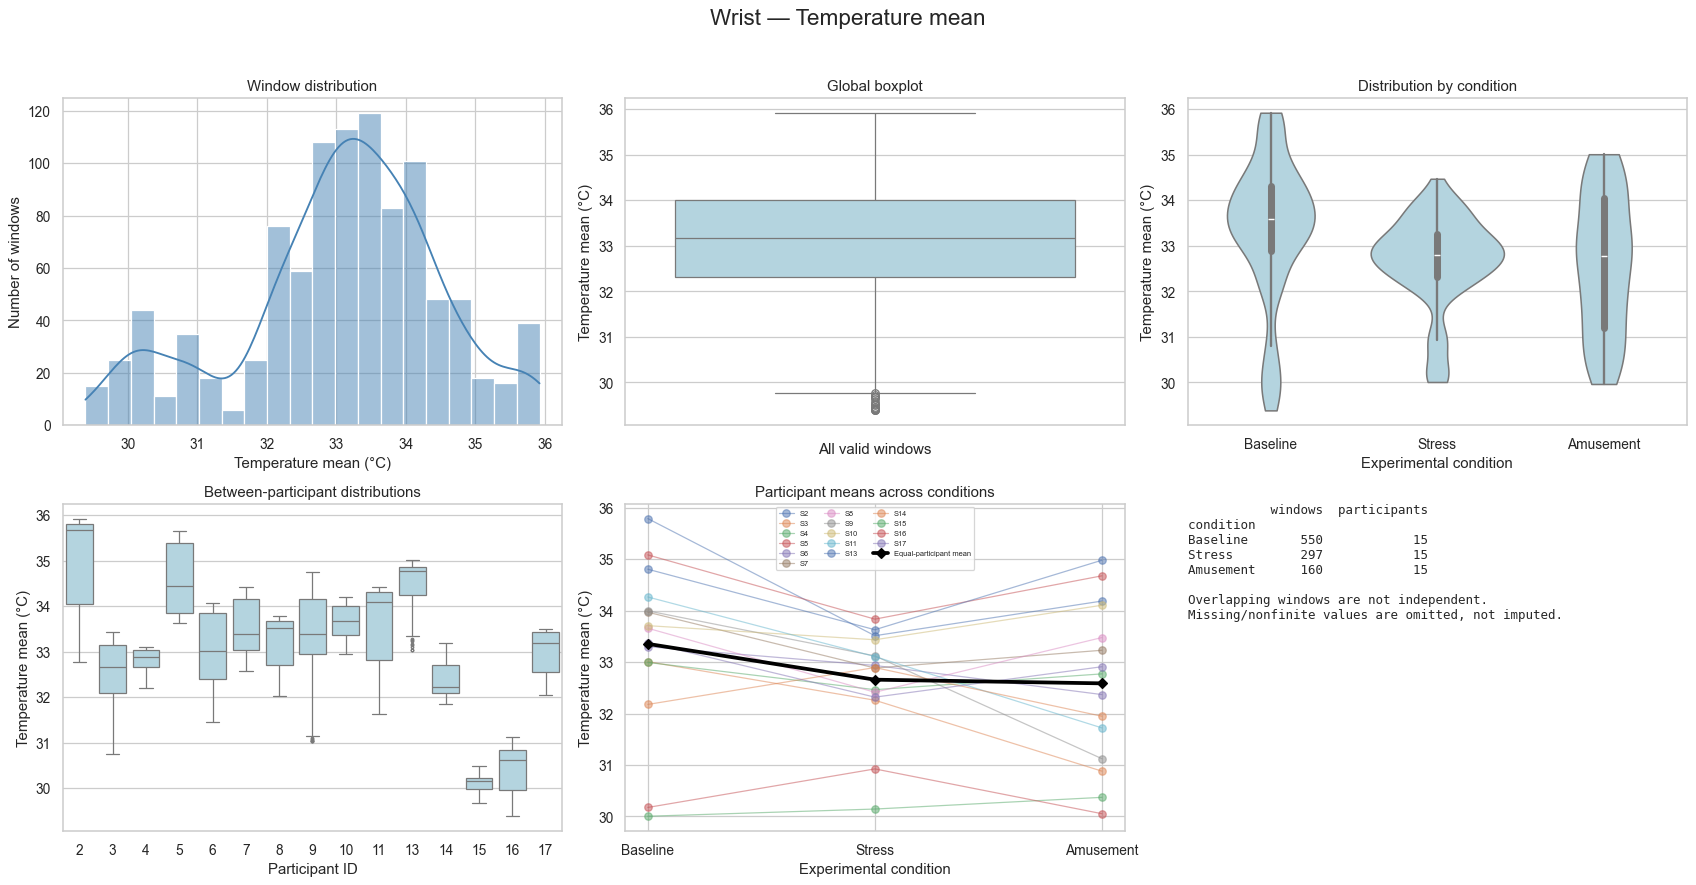

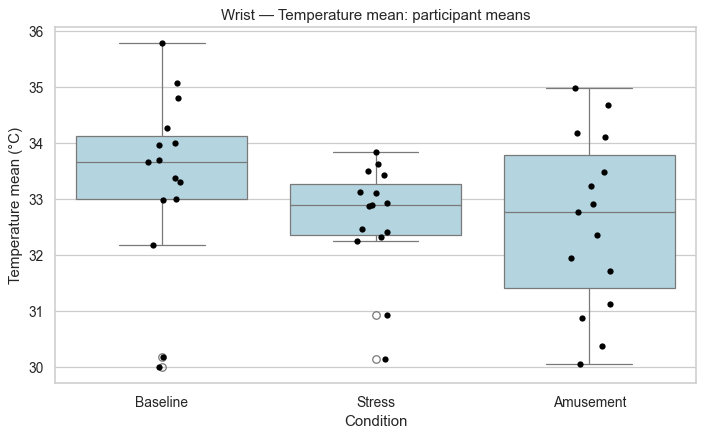

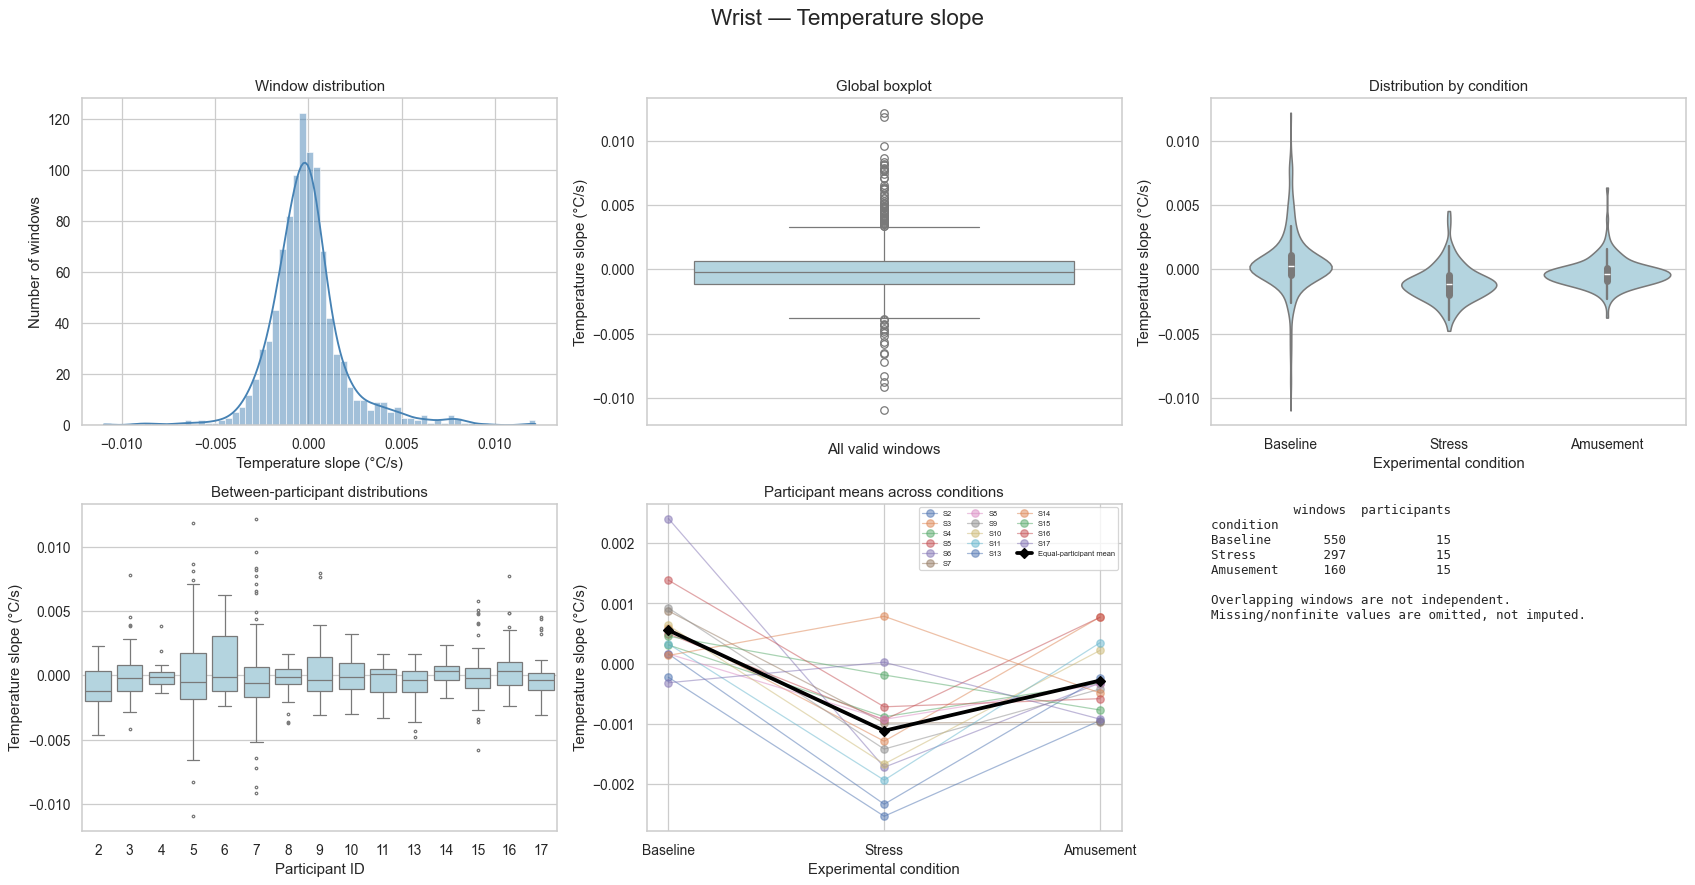

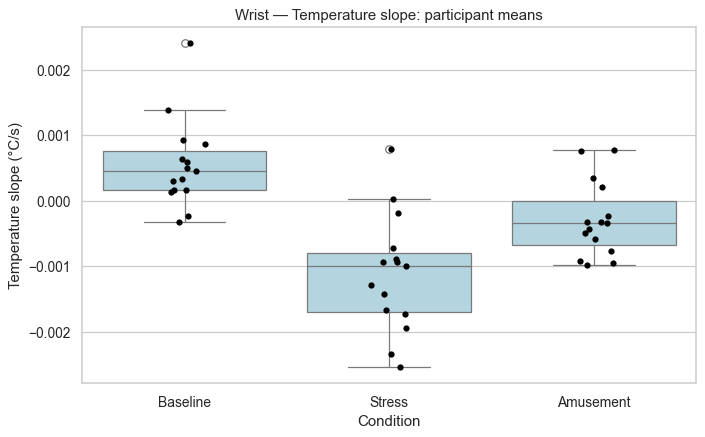

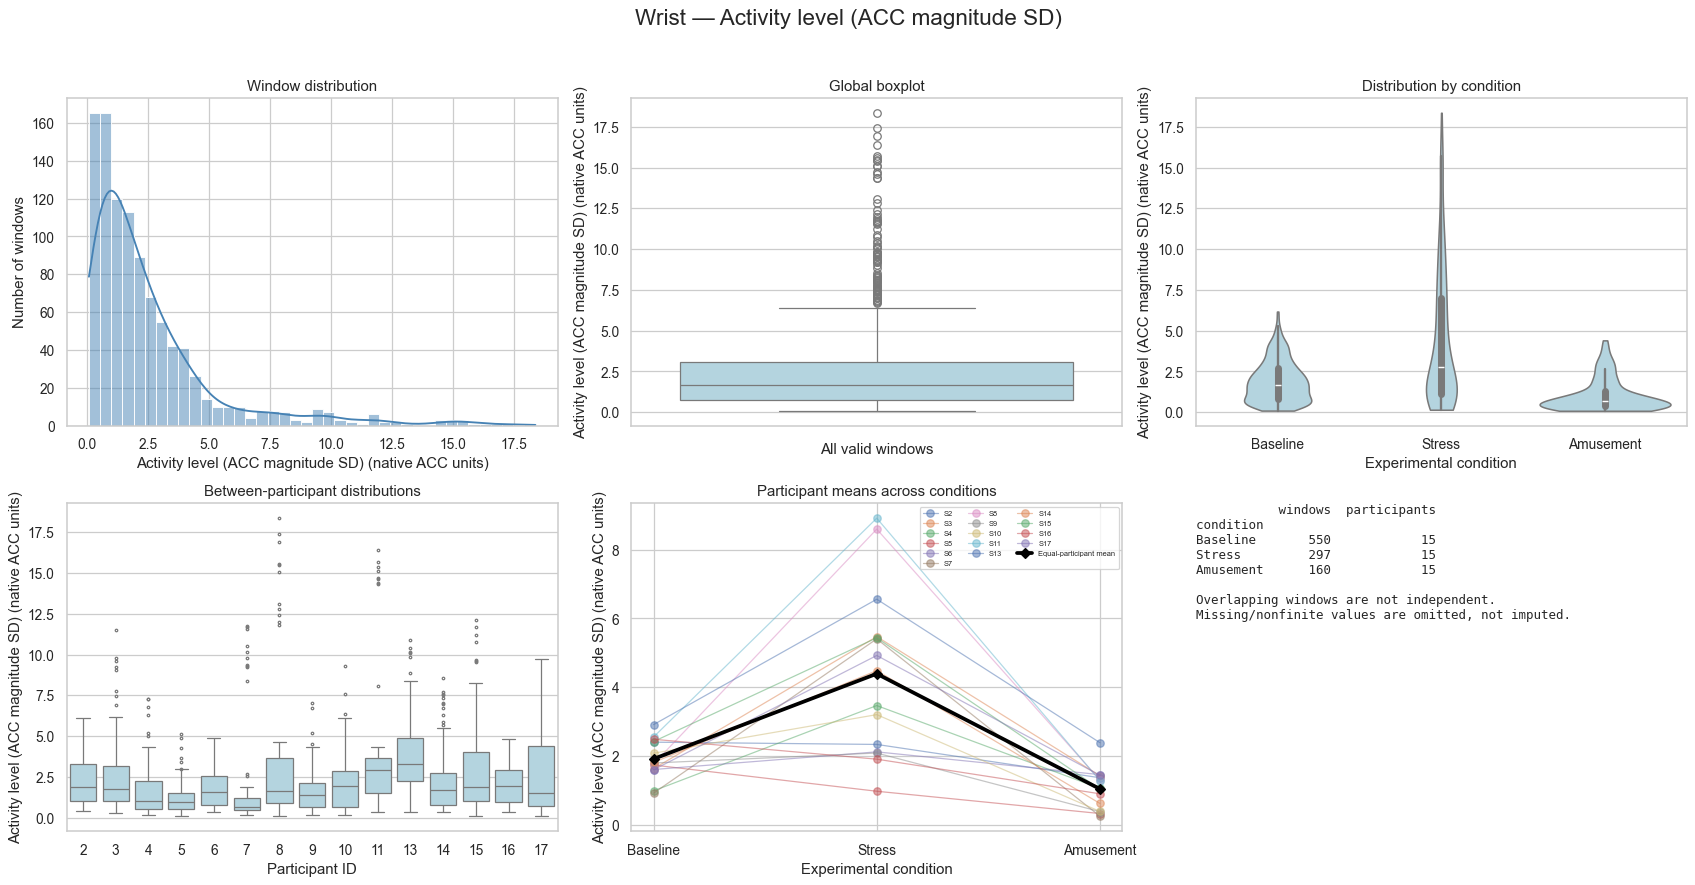

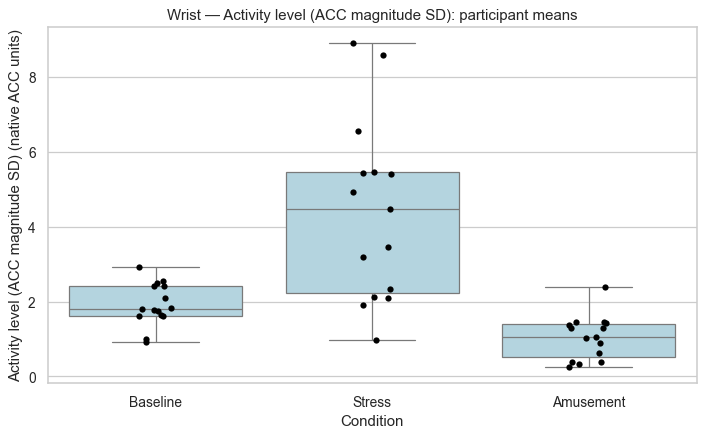

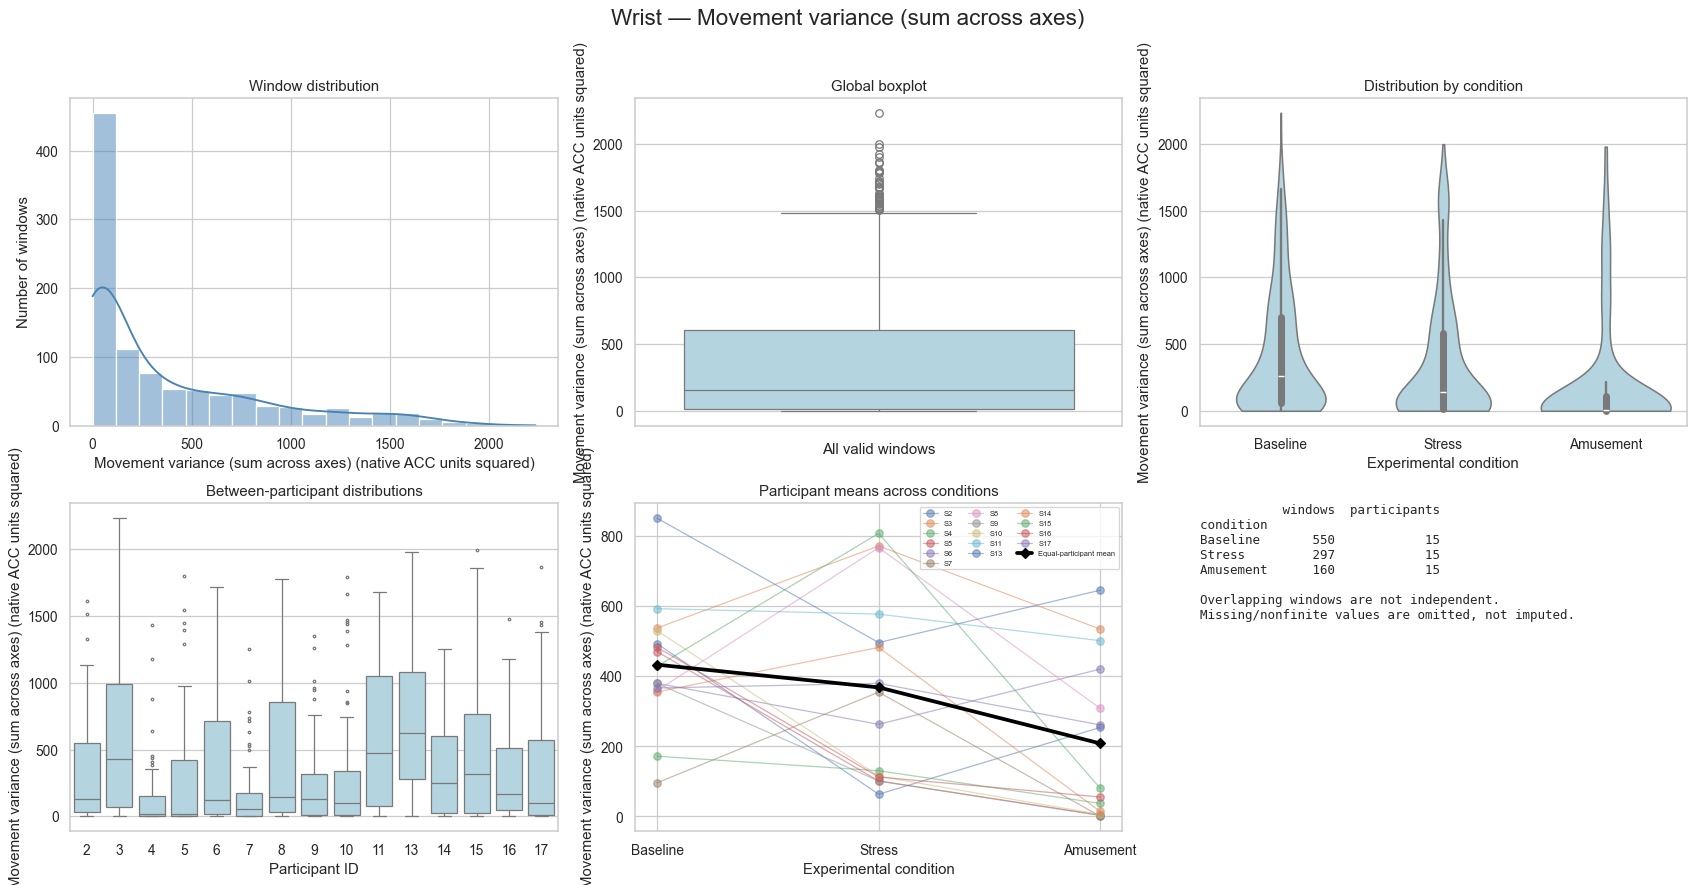

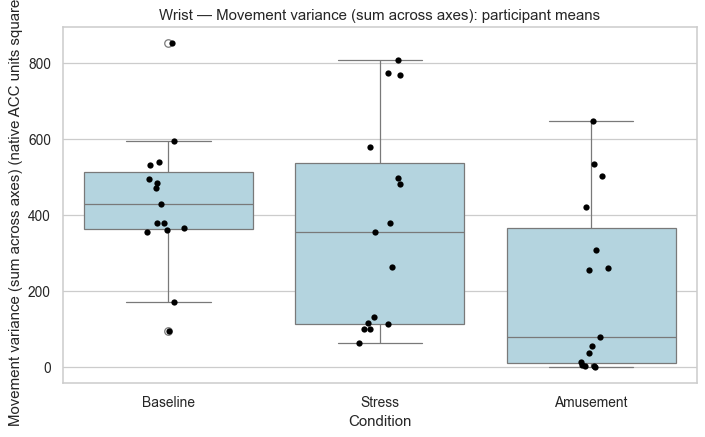

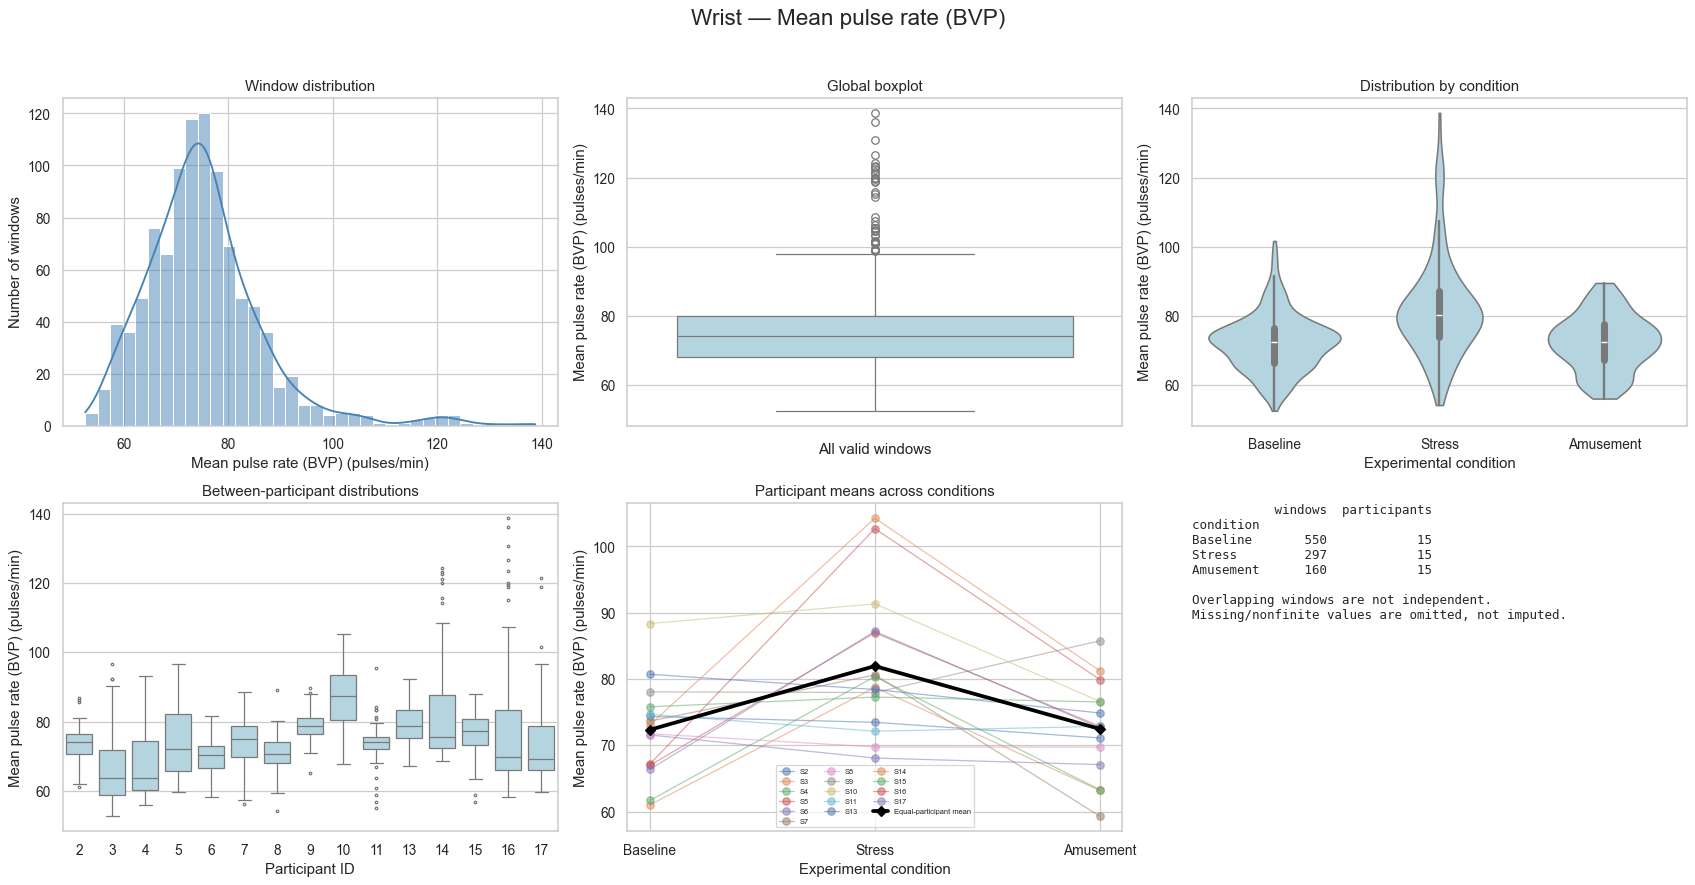

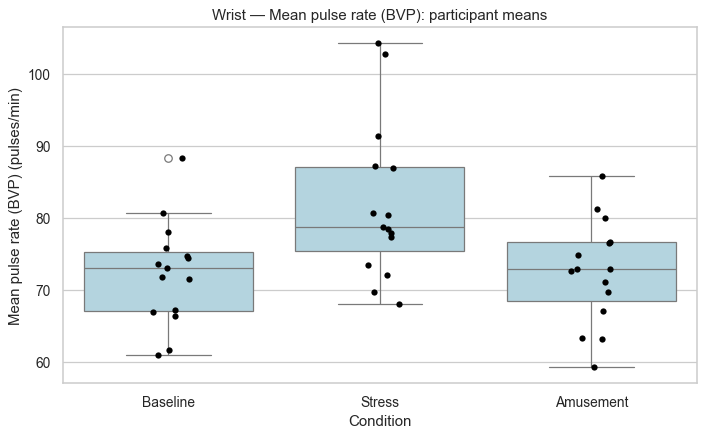

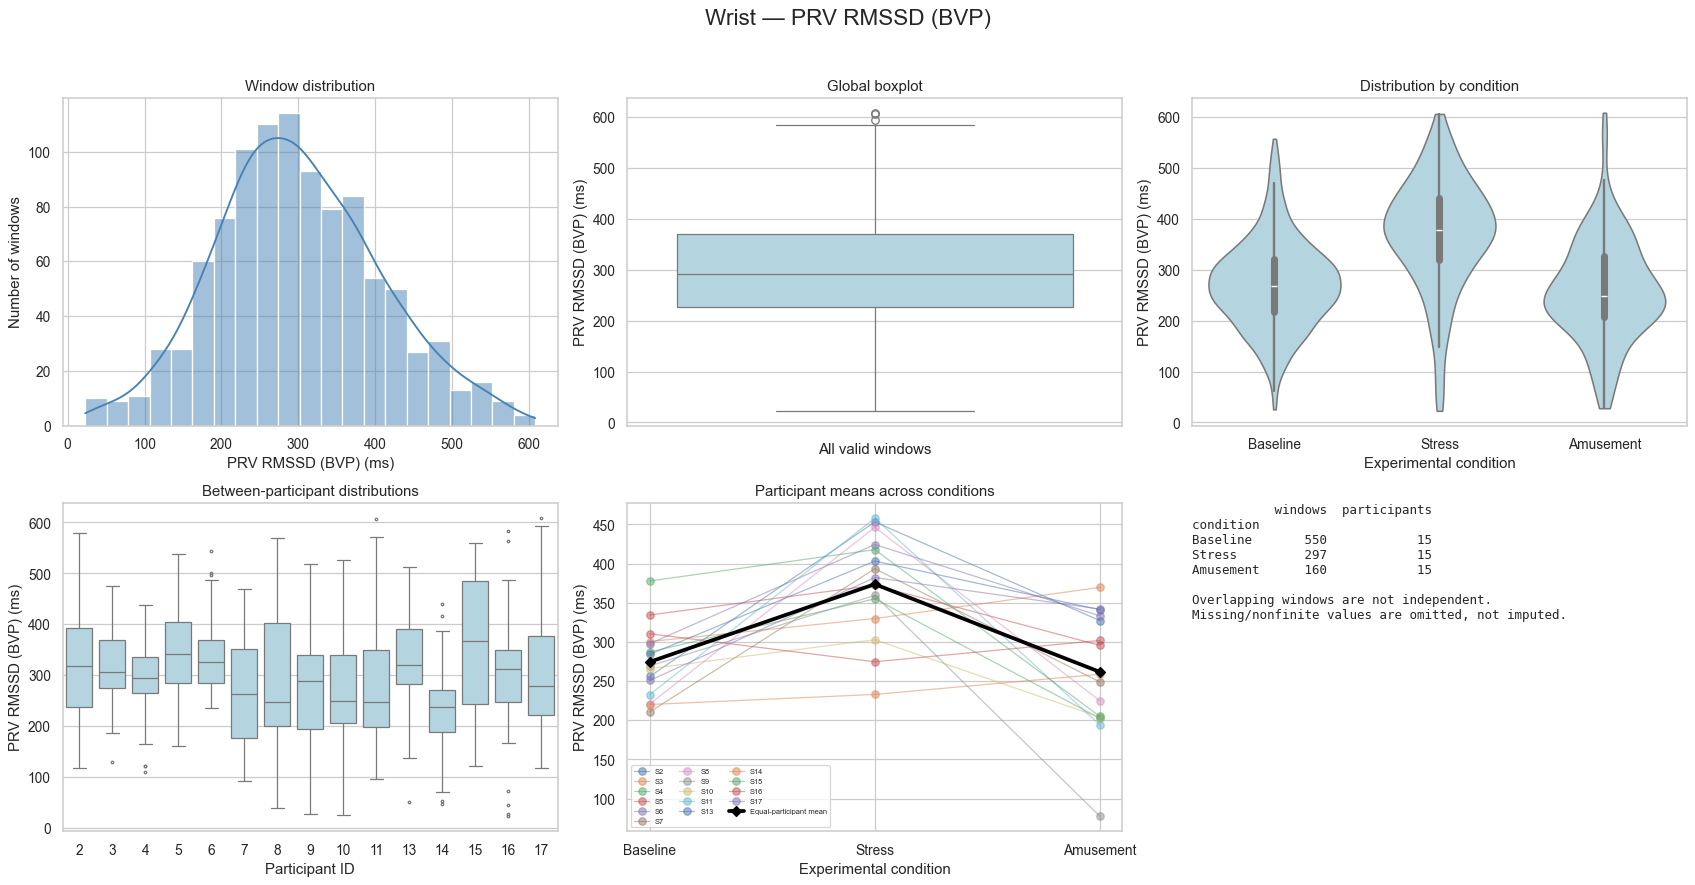

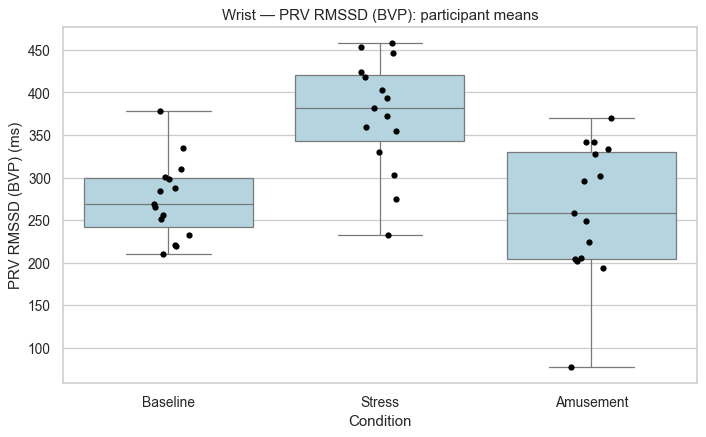

,site,feature,label,condition,n_valid_windows,n_nonfinite,n_subjects,mean,median,IQR,skewness,excess_kurtosis,tukey_flag_count,tukey_flag_fraction
0,chest,chest__EDA__mean,EDA mean,All,1040,0,15,4.579202,3.713273,4.344867,1.540554,3.173281,21,0.020192
1,chest,chest__EDA__mean,EDA mean,Baseline,566,0,15,3.901889,2.813287,4.385793,1.124823,0.710838,2,0.003534
2,chest,chest__EDA__mean,EDA mean,Stress,309,0,15,5.901228,4.274725,4.284744,1.661953,2.815833,20,0.064725
3,chest,chest__EDA__mean,EDA mean,Amusement,165,0,15,4.426799,3.154488,4.128897,0.857426,-0.072359,0,0.000000
4,chest,chest__EDA__tonic_proxy,EDA tonic level (proxy),All,1040,0,15,4.579228,3.713063,4.344861,1.540411,3.172446,21,0.020192
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,wrist,wrist__BVP__mean_pulse_rate,Mean pulse rate (BVP),Amusement,160,0,15,72.406750,72.414363,10.226386,-0.011315,-0.629165,0,0.000000
92,wrist,wrist__BVP__prv_rmssd,PRV RMSSD (BVP),All,1007,0,15,299.594806,292.357134,144.043781,0.197412,-0.095159,3,0.002979
93,wrist,wrist__BVP__prv_rmssd,PRV RMSSD (BVP),Baseline,550,0,15,272.521116,268.004179,104.702831,0.335423,0.480118,18,0.032727
94,wrist,wrist__BVP__prv_rmssd,PRV RMSSD (BVP),Stress,297,0,15,371.036506,378.806555,120.919663,-0.683050,0.717362,12,0.040404


In [9]:
summary_rows=[];flag_rows=[];attention_rows=[]
for r in selected.itertuples():
    f=data[r.site][['subject_id','condition',r.column]].copy()
    f['value']=pd.to_numeric(f[r.column],errors='coerce').replace([np.inf,-np.inf],np.nan)
    finite=f.dropna(subset=['value'])
    for condition in ['All',*ORDER]:
        subset=f if condition=='All' else f[f.condition==condition]
        v=subset.value.dropna();q1,q3=v.quantile([.25,.75]) if len(v) else (np.nan,np.nan)
        spread=q3-q1
        outlier=((v<q1-1.5*spread)|(v>q3+1.5*spread)) if spread>0 else pd.Series(False,index=v.index)
        summary_rows.append(dict(site=r.site,feature=r.column,label=r.label,condition=condition,
            n_valid_windows=len(v),n_nonfinite=int(subset.value.isna().sum()),n_subjects=subset.loc[subset.value.notna(),'subject_id'].nunique(),
            mean=v.mean(),median=v.median(),IQR=spread,
            skewness=float(skew(v,bias=False)) if len(v)>2 and v.nunique()>1 else np.nan,
            excess_kurtosis=float(kurtosis(v,fisher=True,bias=False)) if len(v)>3 and v.nunique()>1 else np.nan,
            tukey_flag_count=int(outlier.sum()),tukey_flag_fraction=float(outlier.mean()) if len(v) else np.nan))
    if finite.empty:continue
    subject_means=finite.groupby(['subject_id','condition'],observed=True).value.mean().unstack().reindex(columns=ORDER)
    means_long=subject_means.reset_index().melt(id_vars='subject_id',var_name='condition',value_name='mean').dropna()
    pooled_iqr=finite.value.quantile(.75)-finite.value.quantile(.25)
    condition_means=subject_means.mean(axis=0)
    condition_spread=condition_means.max()-condition_means.min()
    subject_average=subject_means.mean(axis=1)
    between_iqr=subject_average.quantile(.75)-subject_average.quantile(.25)
    attention_rows.append(dict(site=r.site,feature=r.column,label=r.label,
        descriptive_condition_spread_over_IQR=condition_spread/pooled_iqr if pooled_iqr>0 else np.nan,
        participant_IQR_over_pooled_IQR=between_iqr/pooled_iqr if pooled_iqr>0 else np.nan,
        condition_means=json.dumps({str(k):float(v) for k,v in condition_means.items() if pd.notna(v)})))
    fig,axes=plt.subplots(2,3,figsize=(19,10))
    sns.histplot(finite.value,kde=len(finite)>3 and finite.value.nunique()>2,ax=axes[0,0],color='steelblue')
    axes[0,0].set(title='Window distribution',xlabel=f'{r.label} ({r.unit})',ylabel='Number of windows')
    sns.boxplot(y=finite.value,ax=axes[0,1],color='lightblue')
    axes[0,1].set(title='Global boxplot',ylabel=f'{r.label} ({r.unit})',xlabel='All valid windows')
    sns.violinplot(data=finite,x='condition',y='value',order=ORDER,cut=0,inner='box',ax=axes[0,2],color='lightblue')
    axes[0,2].set(title='Distribution by condition',xlabel='Experimental condition',ylabel=f'{r.label} ({r.unit})')
    subjects=sorted(finite.subject_id.unique())
    sns.boxplot(data=finite,x='subject_id',y='value',order=subjects,ax=axes[1,0],color='lightblue',fliersize=2)
    axes[1,0].set(title='Between-participant distributions',xlabel='Participant ID',ylabel=f'{r.label} ({r.unit})')
    for sid,row in subject_means.iterrows():axes[1,1].plot(ORDER,row.reindex(ORDER),marker='o',alpha=.5,linewidth=1,label=f'S{sid}')
    axes[1,1].plot(ORDER,condition_means.reindex(ORDER),color='black',marker='D',linewidth=3,label='Equal-participant mean')
    axes[1,1].set(title='Participant means across conditions',xlabel='Experimental condition',ylabel=f'{r.label} ({r.unit})')
    axes[1,1].legend(fontsize=6,ncol=3)
    counts=finite.groupby('condition',observed=True).agg(windows=('value','size'),participants=('subject_id','nunique')).reindex(ORDER)
    axes[1,2].axis('off');axes[1,2].text(0,1,counts.to_string()+'\n\nOverlapping windows are not independent.\nMissing/nonfinite values are omitted, not imputed.',va='top',family='monospace',fontsize=10)
    fig.suptitle(f'{r.site.title()} — {r.label}',fontsize=18)
    fig.tight_layout(rect=(0,0,1,.96));savefig(fig,DIST/f'{r.column}.png')
    # Dedicated group comparison figure, readable outside the distribution panel.
    fig,ax=plt.subplots(figsize=(8,5))
    sns.boxplot(data=means_long,x='condition',y='mean',order=ORDER,ax=ax,color='lightblue')
    sns.stripplot(data=means_long,x='condition',y='mean',order=ORDER,ax=ax,color='black',jitter=.10,size=5)
    ax.set(title=f'{r.site.title()} — {r.label}: participant means',xlabel='Condition',ylabel=f'{r.label} ({r.unit})')
    fig.tight_layout();savefig(fig,GROUP/f'{r.column}_participant_means.png')
summary=pd.DataFrame(summary_rows);attention=pd.DataFrame(attention_rows)
summary.to_csv(TABLES/'feature_descriptive_statistics.csv',index=False)
attention.to_csv(TABLES/'descriptive_attention_indicators.csv',index=False)
display(summary)


## Correlations: chest, wrist, fused

Spearman correlations are descriptive. Each modality has a pooled-window heatmap and a participant–condition mean heatmap. Only off-diagonal |rho| > 0.7 are annotated. No p-values are computed. Grouping and overlapping windows can generate associations; even participant–condition rows repeat participants. Pairwise complete counts are saved. Fused uses common valid windows and is not a new sensor modality.

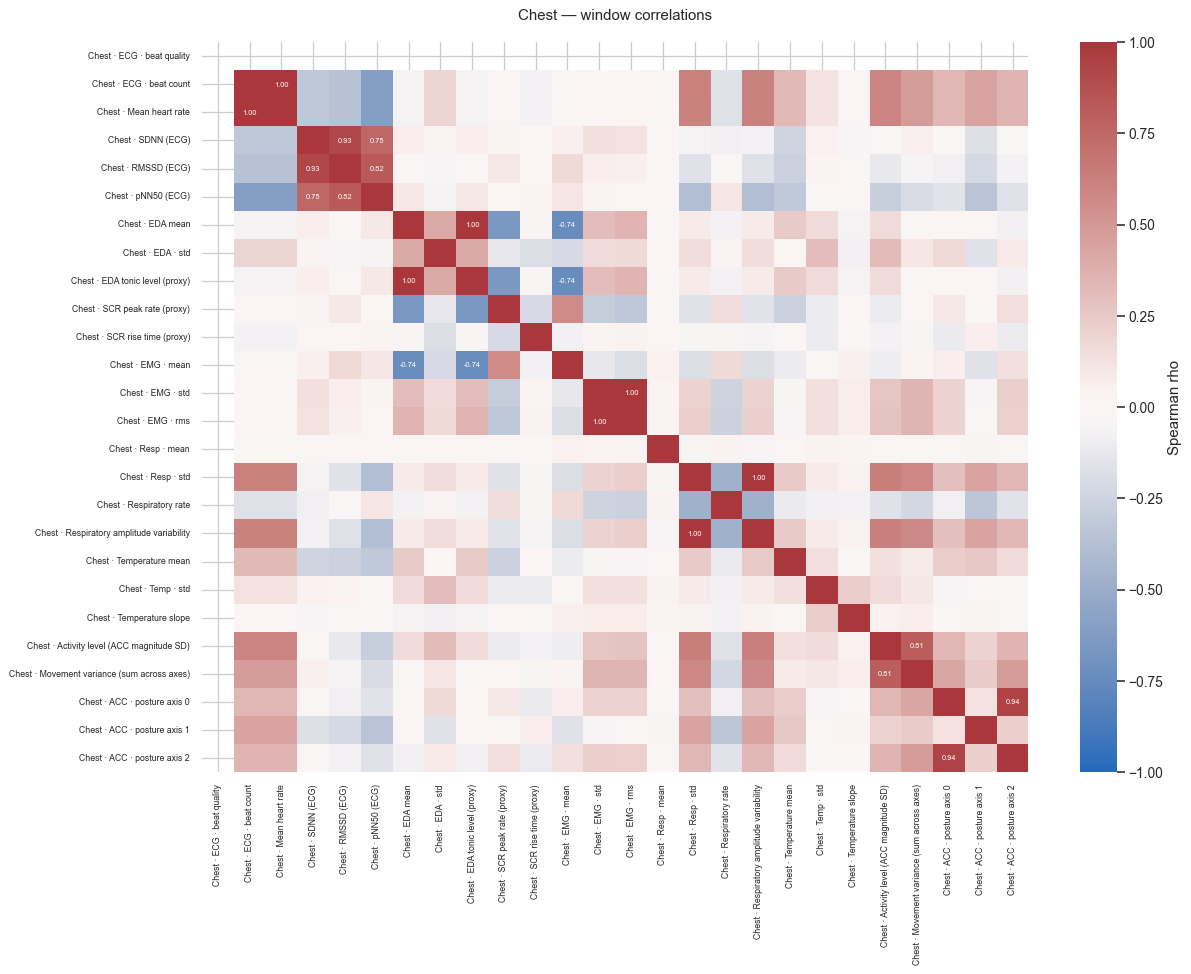

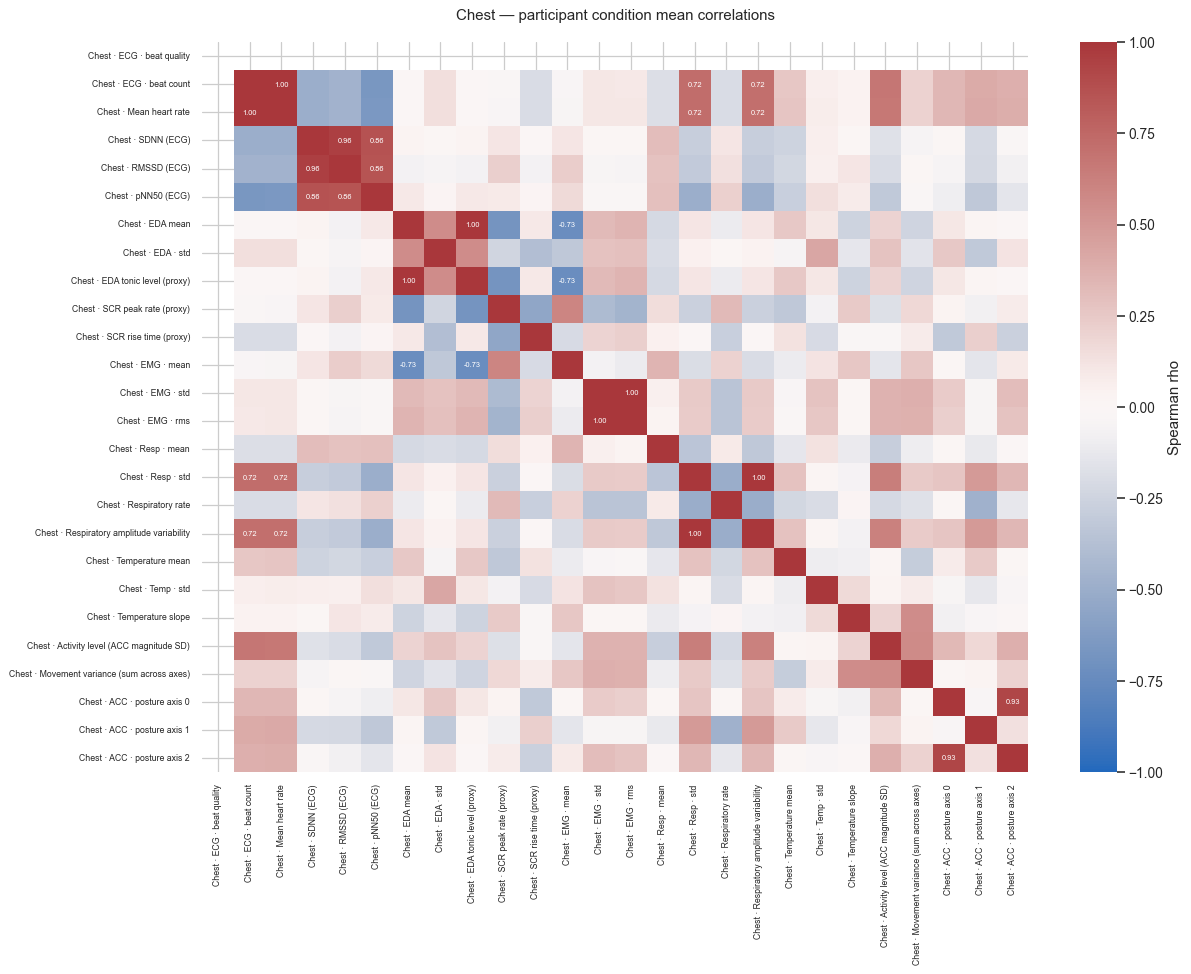

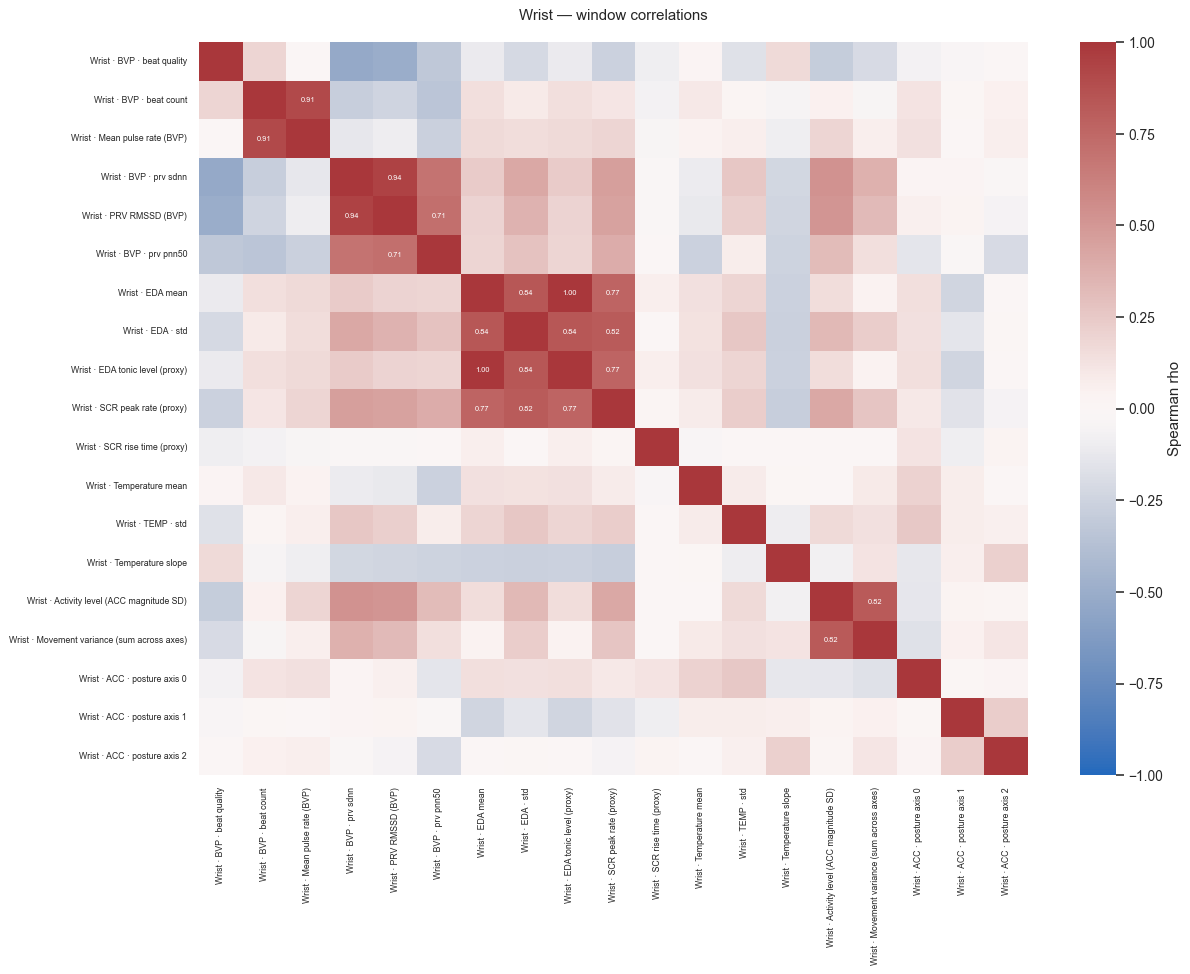

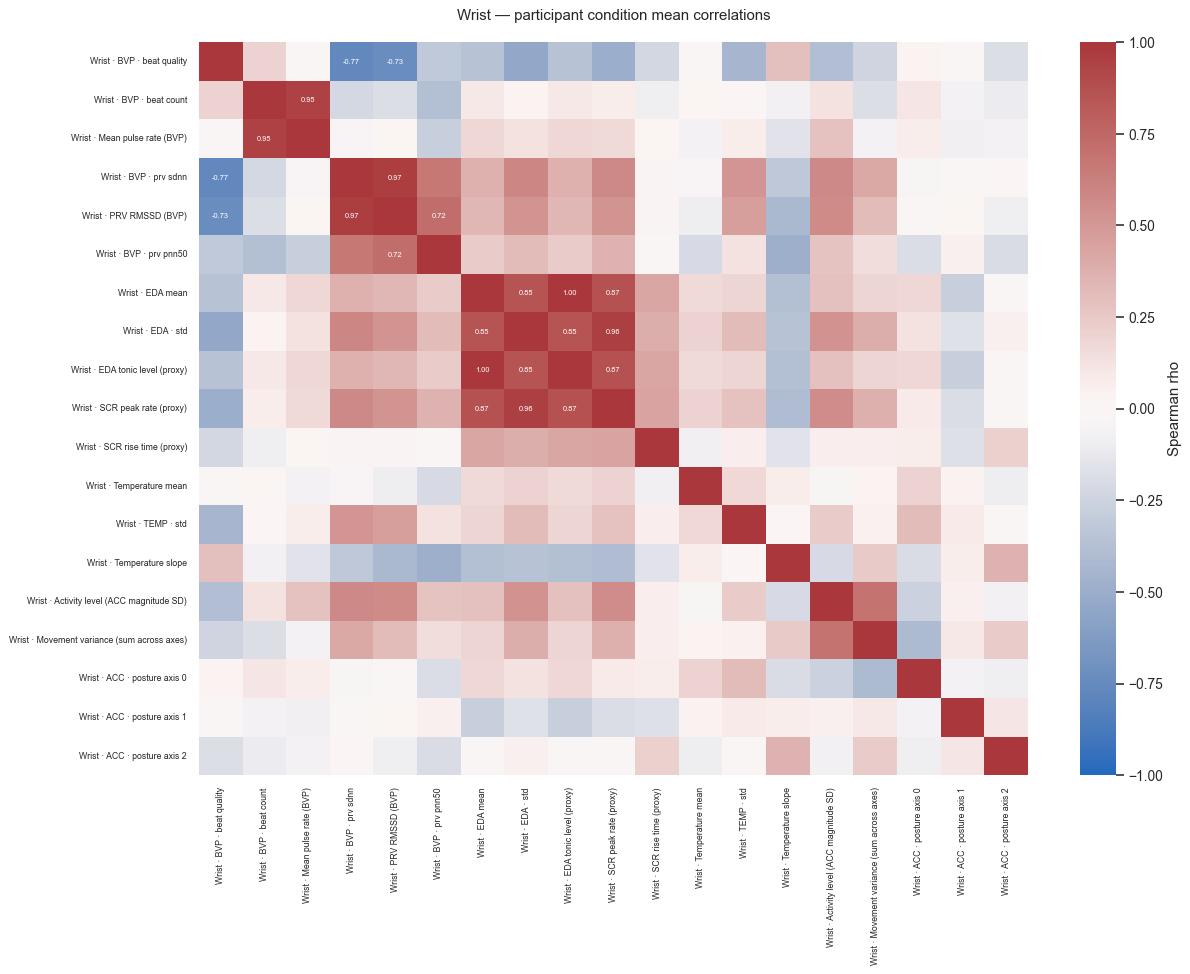

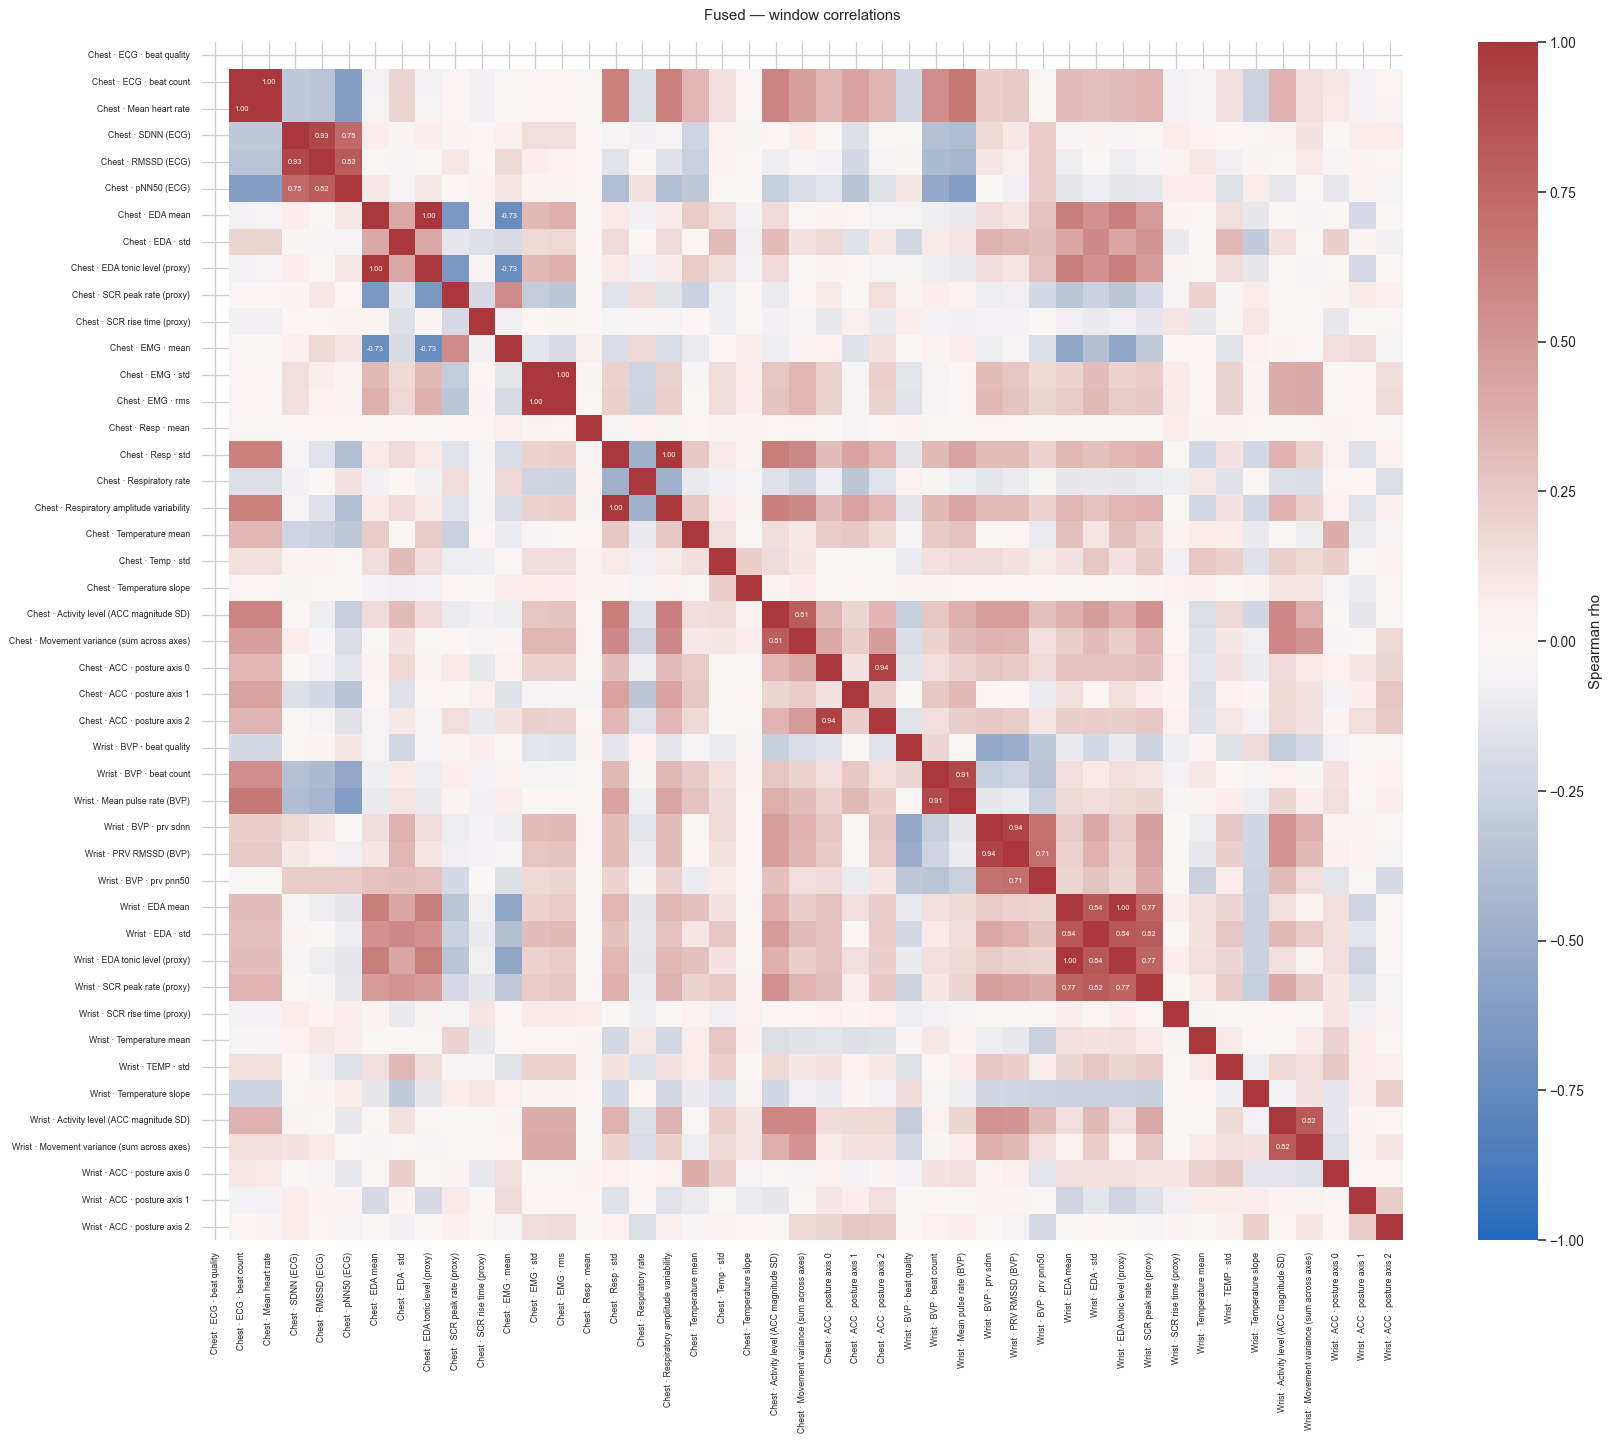

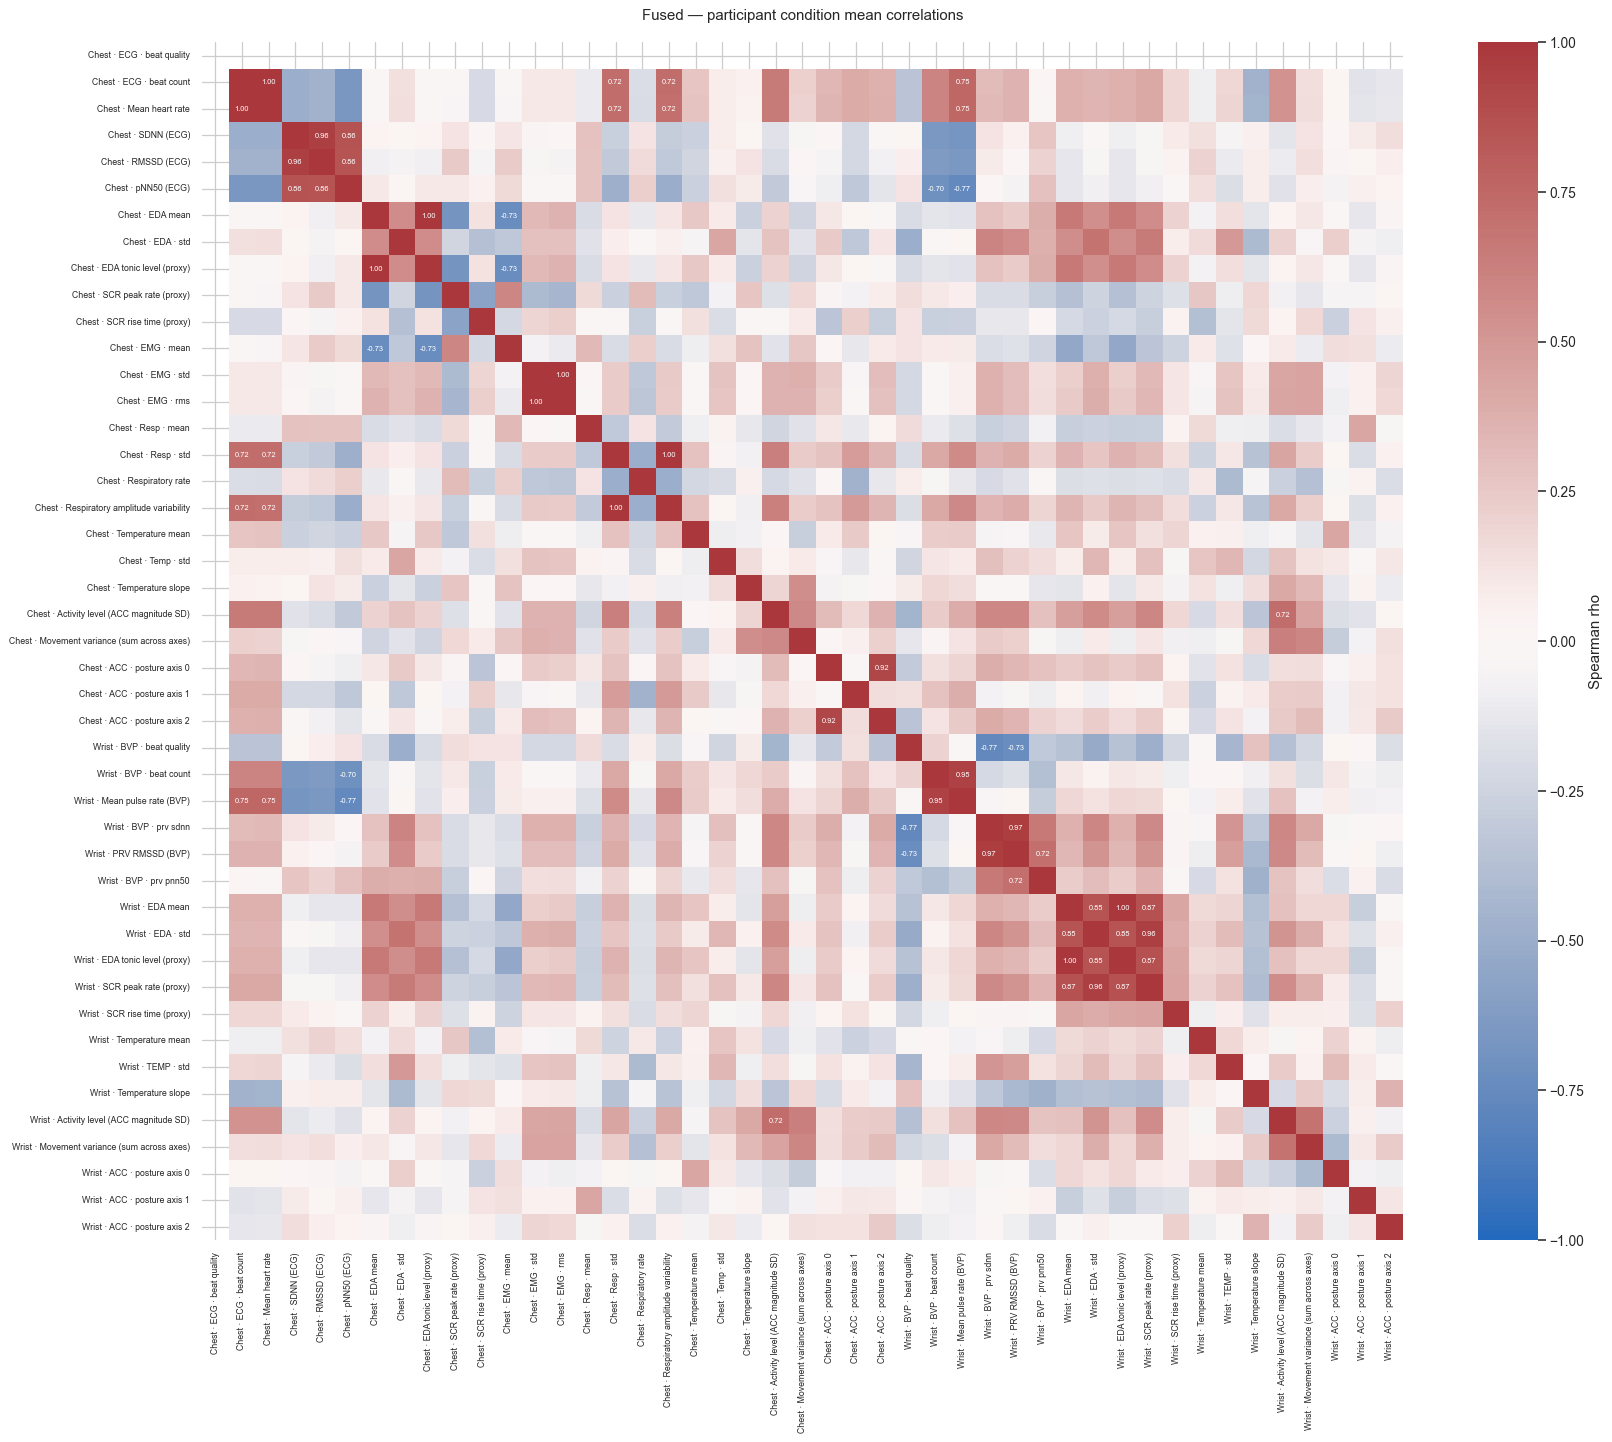

,site,level,feature_a,feature_b,rho,abs_rho,n_pairs
0,chest,window,chest__EDA__mean,chest__EDA__tonic_proxy,0.999999,0.999999,1040
1,chest,window,chest__ECG__beat_count,chest__ECG__mean_hr,0.999503,0.999503,1040
2,chest,window,chest__Resp__std,chest__Resp__amplitude_variability,0.998400,0.998400,1040
3,chest,window,chest__EMG__std,chest__EMG__rms,0.997768,0.997768,1040
4,chest,window,chest__ACC__posture_axis_0,chest__ACC__posture_axis_2,0.941843,0.941843,1040
5,chest,window,chest__ECG__hrv_sdnn,chest__ECG__hrv_rmssd,0.928934,0.928934,1040
6,chest,window,chest__ECG__hrv_rmssd,chest__ECG__hrv_pnn50,0.821337,0.821337,1040
7,chest,window,chest__ACC__activity_level,chest__ACC__movement_variance,0.808102,0.808102,1040
8,chest,window,chest__ECG__hrv_sdnn,chest__ECG__hrv_pnn50,0.754392,0.754392,1040
9,chest,window,chest__EDA__mean,chest__EMG__mean,-0.735426,0.735426,1040


In [10]:
correlated_tables=[]
for site,f in data.items():
    cols=[col for col in names.get(site,[]) if col in f and pd.api.types.is_numeric_dtype(f[col])]
    if len(cols)<2:continue
    numeric=f[cols].replace([np.inf,-np.inf],np.nan)
    for level,values in [('window',numeric),('participant_condition_mean',f.assign(**{col:numeric[col] for col in cols}).groupby(['subject_id','condition'],observed=True)[cols].mean())]:
        matrix=values.corr(method='spearman',min_periods=3)
        matrix.to_csv(TABLES/f'{site}_{level}_spearman_matrix.csv')
        annotation=np.full(matrix.shape,'',dtype=object)
        rows=[]
        for i,a in enumerate(cols):
            for j,b in enumerate(cols):
                rho=matrix.iloc[i,j]
                if i!=j and pd.notna(rho) and abs(rho)>.7:annotation[i,j]=f'{rho:.2f}'
                if i<j and pd.notna(rho) and abs(rho)>.7:
                    rows.append(dict(site=site,level=level,feature_a=a,feature_b=b,rho=rho,abs_rho=abs(rho),
                        n_pairs=int(values[[a,b]].dropna().shape[0])))
        pairs=pd.DataFrame(rows,columns=['site','level','feature_a','feature_b','rho','abs_rho','n_pairs'])
        pairs=pairs.sort_values('abs_rho',ascending=False)
        pairs.to_csv(TABLES/f'{site}_{level}_high_correlation_pairs.csv',index=False)
        correlated_tables.append(pairs)
        size=max(11,len(cols)*.36)
        fig,ax=plt.subplots(figsize=(size+3,size))
        sns.heatmap(matrix,vmin=-1,vmax=1,center=0,cmap='vlag',annot=annotation,fmt='',annot_kws={'fontsize':6},
                    xticklabels=[pretty(x) for x in cols],yticklabels=[pretty(x) for x in cols],ax=ax,cbar_kws={'label':'Spearman rho'})
        ax.set_title(f'{site.title()} — {level.replace("_"," ")} correlations',pad=18)
        ax.tick_params(axis='both',labelsize=7)
        plt.setp(ax.get_xticklabels(),rotation=90)
        fig.tight_layout();savefig(fig,CORR/f'{site}_{level}_spearman.png')
high_pairs=pd.concat(correlated_tables,ignore_index=True) if correlated_tables else pd.DataFrame()
display(high_pairs.head(30))


## Wrist versus chest: comparable and related measures

Comparisons use exactly matched valid windows, then average within participant and condition. Spearman is shown per condition across participants to avoid treating all windows as independent. No significance tests are performed.

Heart rate versus pulse rate are related measures but not identical. HRV versus PRV, electrode-site EDA, and local temperatures are not assumed interchangeable. ACC comparisons require unit confirmation.Repeated-measures uncertainty is not inferred from these plots.

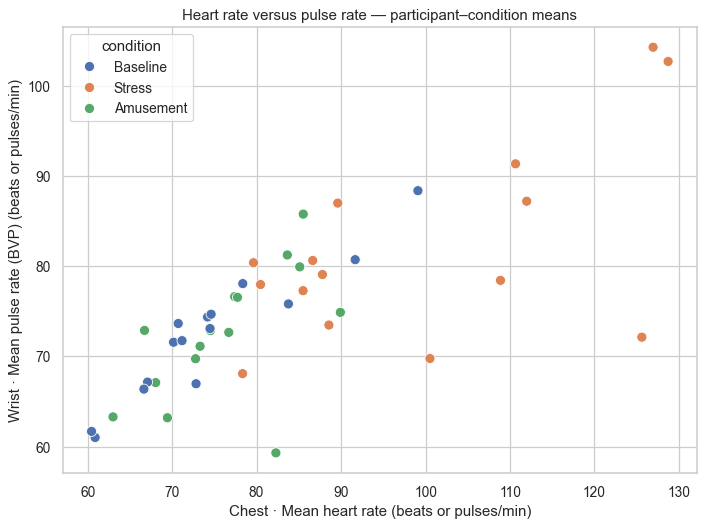

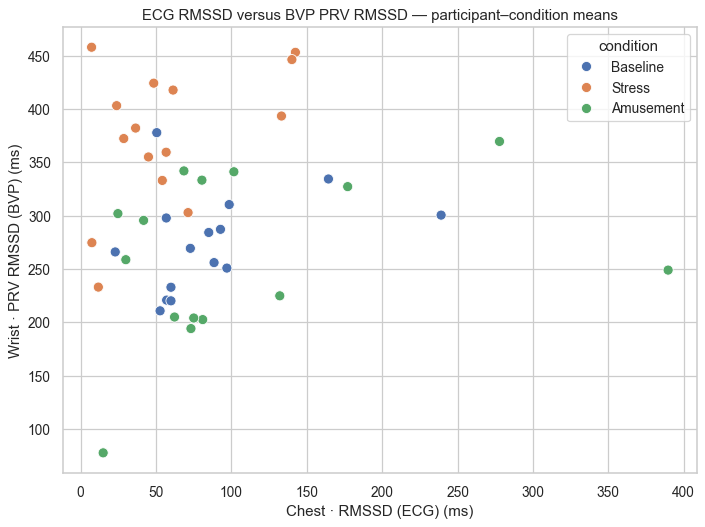

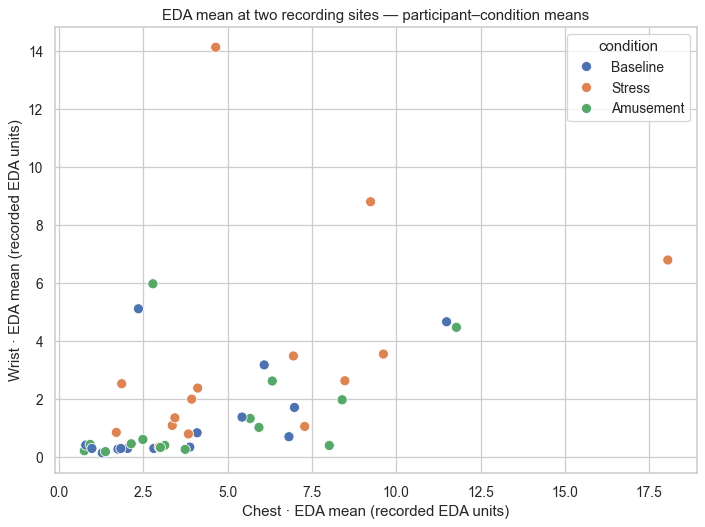

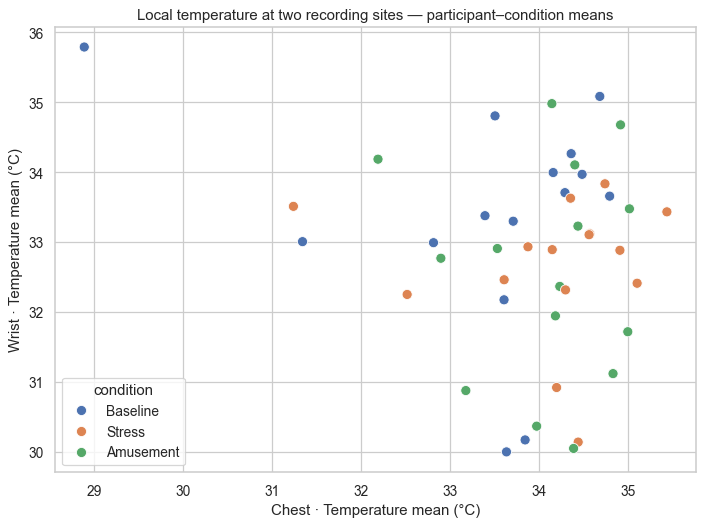

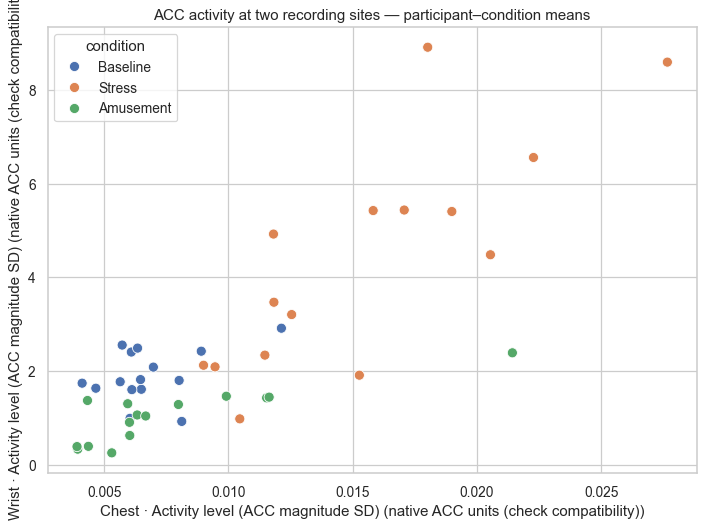

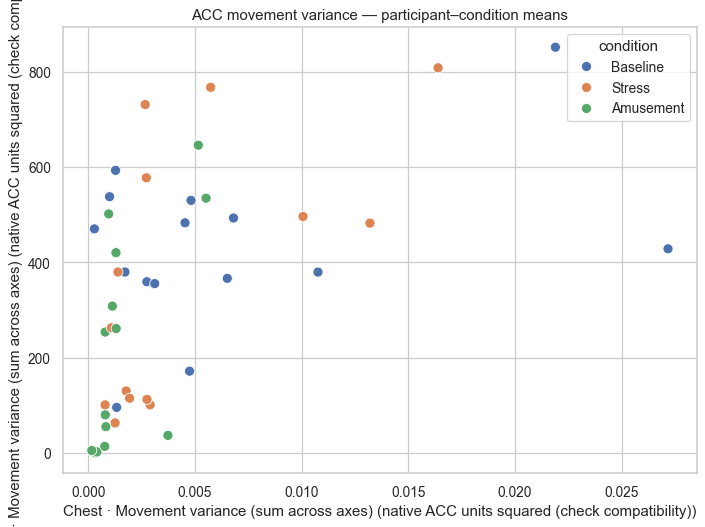

,feature_chest,feature_wrist,condition,n_subjects,rho,bland_altman_enabled
0,chest__ECG__mean_hr,wrist__BVP__mean_pulse_rate,Baseline,15,0.935714,False
1,chest__ECG__mean_hr,wrist__BVP__mean_pulse_rate,Stress,15,0.517857,False
2,chest__ECG__mean_hr,wrist__BVP__mean_pulse_rate,Amusement,15,0.642857,False
3,chest__ECG__hrv_rmssd,wrist__BVP__prv_rmssd,Baseline,15,0.346429,False
4,chest__ECG__hrv_rmssd,wrist__BVP__prv_rmssd,Stress,15,0.278571,False
5,chest__ECG__hrv_rmssd,wrist__BVP__prv_rmssd,Amusement,15,0.310714,False
6,chest__EDA__mean,wrist__EDA__mean,Baseline,15,0.671429,False
7,chest__EDA__mean,wrist__EDA__mean,Stress,15,0.689286,False
8,chest__EDA__mean,wrist__EDA__mean,Amusement,15,0.528571,False
9,chest__Temp__mean,wrist__TEMP__mean,Baseline,15,0.214286,False


Bland–Altman plots require explicit documented approval; correlation does not demonstrate agreement.


In [11]:
comparison_specs=[
 ('chest__ECG__mean_hr','wrist__BVP__mean_pulse_rate','Heart rate versus pulse rate','beats or pulses/min',False),
 ('chest__ECG__hrv_rmssd','wrist__BVP__prv_rmssd','ECG RMSSD versus BVP PRV RMSSD','ms',False),
 ('chest__EDA__mean','wrist__EDA__mean','EDA mean at two recording sites','recorded EDA units',False),
 ('chest__Temp__mean','wrist__TEMP__mean','Local temperature at two recording sites','°C',False),
 ('chest__ACC__activity_level','wrist__ACC__activity_level','ACC activity at two recording sites','native ACC units (check compatibility)',False),
 ('chest__ACC__movement_variance','wrist__ACC__movement_variance','ACC movement variance','native ACC units squared (check compatibility)',False),
]
# Set to True only after documenting same construct, compatible units and meaningful differences.
BA_APPROVAL = {}  # Example key: ('chest column', 'wrist column'): 'documented rationale'
agreement_rows=[]
f=data['fused']
for a,b,title,unit,_ in comparison_specs:
    if a not in f or b not in f:continue
    pairs=f[['subject_id','condition',a,b]].replace([np.inf,-np.inf],np.nan).dropna()
    means=pairs.groupby(['subject_id','condition'],observed=True)[[a,b]].mean().reset_index()
    fig,ax=plt.subplots(figsize=(8,6))
    sns.scatterplot(data=means,x=a,y=b,hue='condition',hue_order=ORDER,ax=ax,s=65)
    ax.set(title=title+' — participant–condition means',xlabel=pretty(a)+' ('+unit+')',ylabel=pretty(b)+' ('+unit+')')
    fig.tight_layout();savefig(fig,GROUP/f'paired_{a}__{b}.png')
    for condition in ORDER:
        g=means[means.condition==condition]
        rho=float(spearmanr(g[a],g[b]).statistic) if len(g)>=3 and g[a].nunique()>1 and g[b].nunique()>1 else np.nan
        agreement_rows.append(dict(feature_chest=a,feature_wrist=b,condition=condition,n_subjects=len(g),rho=rho,
                                   bland_altman_enabled=(a,b) in BA_APPROVAL))
    if (a,b) in BA_APPROVAL:
        for condition in ORDER:
            g=means[means.condition==condition]
            if len(g)<3:continue
            mid=(g[a]+g[b])/2;difference=g[b]-g[a]
            bias=difference.mean();sd=difference.std(ddof=1)
            fig,ax=plt.subplots(figsize=(8,5))
            ax.scatter(mid,difference)
            for value,label in [(bias,'Mean difference'),(bias-1.96*sd,'Lower descriptive limit'),(bias+1.96*sd,'Upper descriptive limit')]:
                ax.axhline(value,linestyle='--',label=f'{label}: {value:.3g}')
            ax.set(title=f'{title} — {condition} (n={len(g)})',xlabel=f'Mean of paired values ({unit})',ylabel=f'Wrist minus chest ({unit})')
            ax.legend();fig.tight_layout();savefig(fig,GROUP/f'BA_{a}__{b}_{condition}.png')
agreement=pd.DataFrame(agreement_rows)
agreement.to_csv(TABLES/'wrist_chest_correlations.csv',index=False)
display(agreement)
print('Bland–Altman plots require explicit documented approval; correlation does not demonstrate agreement.')


## QC context and report

The report highlights descriptive patterns, not significant condition effects. Standardized mean ranges and variability ratios are navigation aids, not feature-selection criteria. Outlier flags are not automatic artifact diagnoses. Potential future SHAP/ALE attention is explicitly separated from model input selection and never computed here.

In [12]:
# QC summary and numerical tables only; report narrative is in the Markdown cell below.
qc_view = qc.loc[qc.label.isin(LABELS)].copy()
qc_view['valid_bool'] = boolean(qc_view.valid)
qc_summary = qc_view.groupby(['site', 'channel', 'label']).agg(
    n_windows=('valid_bool', 'size'), n_valid=('valid_bool', 'sum')
)
qc_summary['excluded_percent'] = 100 * (1 - qc_summary.n_valid / qc_summary.n_windows)
qc_summary.to_csv(TABLES / 'qc_exclusions_by_channel_condition.csv')
display(qc_summary)

all_stats = summary.loc[summary.condition.eq('All')].copy()
condition_attention = attention.sort_values(
    'descriptive_condition_spread_over_IQR', ascending=False
).head(10)
participant_attention = attention.sort_values(
    'participant_IQR_over_pooled_IQR', ascending=False
).head(10)
outliers = all_stats.sort_values('tukey_flag_fraction', ascending=False).head(10)

condition_attention.to_csv(TABLES / 'condition_attention_summary.csv', index=False)
participant_attention.to_csv(TABLES / 'participant_variability_summary.csv', index=False)
outliers.to_csv(TABLES / 'outlier_attention_summary.csv', index=False)

manifest = {
    'role': 'descriptive_exploratory',
    'no_training': True,
    'no_feature_selection': True,
    'dpi': 300,
    'inputs': {
        key: {'file': path.name, 'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
        for key, path in paths.items()
    },
    'correlation': 'Spearman, descriptive; |rho| > 0.7 annotations',
    'outliers': 'Tukey flags only; no removal',
    'bland_altman_approval': {str(key): value for key, value in BA_APPROVAL.items()},
}
(TABLES / 'eda_manifest.json').write_text(
    json.dumps(manifest, indent=2), encoding='utf-8'
)
print('EDA tables and manifest saved. The report is an editable Markdown cell below.')


n_windows  n_valid  excluded_percent
site  channel label                                      
chest ACC     1            566      566          0.000000
              2            311      311          0.000000
              3            165      165          0.000000
      ECG     1            566      566          0.000000
              2            311      311          0.000000
              3            165      165          0.000000
      EDA     1            566      566          0.000000
              2            311      311          0.000000
              3            165      165          0.000000
      EMG     1            566      566          0.000000
              2            311      311          0.000000
              3            165      165          0.000000
      Resp    1            566      566          0.000000
              2            311      311          0.000000
              3            165      165          0.000000
      Temp    1            566      566          0.000000
              2            311      309          0.643087
              3            165      165          0.000000
wrist ACC     1            566      565          0.176678
              2            311      311          0.000000
              3            165      164          0.606061
      BVP     1            566      551          2.650177
              2            311      297          4.501608
              3            165      161          2.424242
      EDA     1            566      566          0.000000
              2            311      311          0.000000
              3            165      165          0.000000
      TEMP    1            566      566          0.000000
              2            311      311          0.000000
              3            165      165          0.000000

EDA tables and manifest saved. The report is an editable Markdown cell below.


<!-- feature-eda-report -->
> **Saved-run report.** The tables below were transferred from the previously executed report, without changing their values. They are an editable snapshot, not live Python output. If the inputs or EDA settings change, review and update these Markdown tables against the newly generated CSVs before publishing or exporting.

# Feature EDA report



Exploratory, descriptive analysis only. No models, feature selection or SHAP were computed.

Window distributions are weighted by available windows; participant-condition means are used for equal-participant descriptions.

The following have the largest range of equal-participant condition means relative to pooled window IQR. This ranking is not a significance test, effect-size estimator for inference, or feature selection. Inspect the condition violins and participant trajectories before describing visible differences.

| site | label | descriptive_condition_spread_over_IQR | condition_means |
| --- | --- | --- | --- |
| wrist | SCR peak rate (proxy) | 1.59 | {"Baseline": 1.2760579658605977, "Stress": 7.319920738191032, "Amusement": 0.9563636363636364} |
| chest | Movement variance (sum across axes) | 1.53 | {"Baseline": 0.006208427591735791, "Stress": 0.0044810360804587715, "Amusement": 0.0015460436596014698} |
| wrist | Activity level (ACC magnitude SD) | 1.45 | {"Baseline": 1.919245738464405, "Stress": 4.39493813974527, "Amusement": 1.0471913354272622} |
| chest | Mean heart rate | 1.26 | {"Baseline": 74.41514662212037, "Stress": 99.22882224439552, "Amusement": 76.40981649865645} |
| chest | Activity level (ACC magnitude SD) | 1.19 | {"Baseline": 0.006750758499958042, "Stress": 0.015417534237584792, "Amusement": 0.007666297305119232} |
| chest | Respiratory amplitude variability | 0.961 | {"Baseline": 2.6406366653466296, "Stress": 4.346619782991636, "Amusement": 3.0424361184205746} |
| wrist | Temperature slope | 0.932 | {"Baseline": 0.0005535070821350081, "Stress": -0.0011176174953300467, "Amusement": -0.00028313270029069556} |
| wrist | EDA mean | 0.902 | {"Baseline": 1.3196000119696303, "Stress": 3.4594368005923752, "Amusement": 1.3695236454694166} |
| wrist | EDA tonic level (proxy) | 0.901 | {"Baseline": 1.3196315025090934, "Stress": 3.4588543284561504, "Amusement": 1.3695782398645866} |
| chest | SDNN (ECG) | 0.799 | {"Baseline": 101.9477663288306, "Stress": 74.55433340474103, "Amusement": 124.44385518941336} |

## Between-participant variability

Participant average IQR divided by pooled window IQR; missing conditions and differing window counts can affect this description.

| site | label | participant_IQR_over_pooled_IQR |
| --- | --- | --- |
| chest | EDA tonic level (proxy) | 0.919 |
| chest | EDA mean | 0.919 |
| wrist | SCR peak rate (proxy) | 0.843 |
| chest | pNN50 (ECG) | 0.833 |
| chest | Temperature mean | 0.803 |
| wrist | EDA mean | 0.772 |
| wrist | EDA tonic level (proxy) | 0.772 |
| chest | Mean heart rate | 0.768 |
| wrist | Mean pulse rate (BVP) | 0.707 |
| chest | Movement variance (sum across axes) | 0.69 |

## Potential redundancy

Pairs with absolute Spearman correlation above 0.7 are saved for each modality and aggregation level. Correlations can reflect condition or participant differences and are not causal evidence.

| site | level | feature_a | feature_b | rho | abs_rho | n_pairs |
| --- | --- | --- | --- | --- | --- | --- |
| chest | window | chest__EDA__mean | chest__EDA__tonic_proxy | 1 | 1 | 1040 |
| chest | window | chest__ECG__beat_count | chest__ECG__mean_hr | 1 | 1 | 1040 |
| chest | window | chest__Resp__std | chest__Resp__amplitude_variability | 0.998 | 0.998 | 1040 |
| chest | window | chest__EMG__std | chest__EMG__rms | 0.998 | 0.998 | 1040 |
| chest | window | chest__ACC__posture_axis_0 | chest__ACC__posture_axis_2 | 0.942 | 0.942 | 1040 |
| chest | window | chest__ECG__hrv_sdnn | chest__ECG__hrv_rmssd | 0.929 | 0.929 | 1040 |
| chest | window | chest__ECG__hrv_rmssd | chest__ECG__hrv_pnn50 | 0.821 | 0.821 | 1040 |
| chest | window | chest__ACC__activity_level | chest__ACC__movement_variance | 0.808 | 0.808 | 1040 |
| chest | window | chest__ECG__hrv_sdnn | chest__ECG__hrv_pnn50 | 0.754 | 0.754 | 1040 |
| chest | window | chest__EDA__mean | chest__EMG__mean | -0.735 | 0.735 | 1040 |
| chest | window | chest__EDA__tonic_proxy | chest__EMG__mean | -0.735 | 0.735 | 1040 |
| chest | participant_condition_mean | chest__EDA__mean | chest__EDA__tonic_proxy | 1 | 1 | 45 |
| chest | participant_condition_mean | chest__ECG__beat_count | chest__ECG__mean_hr | 1 | 1 | 45 |
| chest | participant_condition_mean | chest__Resp__std | chest__Resp__amplitude_variability | 0.999 | 0.999 | 45 |
| chest | participant_condition_mean | chest__EMG__std | chest__EMG__rms | 0.997 | 0.997 | 45 |
| chest | participant_condition_mean | chest__ECG__hrv_sdnn | chest__ECG__hrv_rmssd | 0.956 | 0.956 | 45 |
| chest | participant_condition_mean | chest__ACC__posture_axis_0 | chest__ACC__posture_axis_2 | 0.927 | 0.927 | 45 |
| chest | participant_condition_mean | chest__ECG__hrv_sdnn | chest__ECG__hrv_pnn50 | 0.861 | 0.861 | 45 |
| chest | participant_condition_mean | chest__ECG__hrv_rmssd | chest__ECG__hrv_pnn50 | 0.856 | 0.856 | 45 |
| chest | participant_condition_mean | chest__EDA__mean | chest__EMG__mean | -0.729 | 0.729 | 45 |

## Outliers and possible measurement issues

Tukey-fence flags are descriptive. They may reflect physiological variation, condition differences, skewness, or artifacts. No flagged window was removed by this notebook; raw signals and QC must be inspected before an artifact claim.

| site | label | n_valid_windows | n_nonfinite | skewness | excess_kurtosis | tukey_flag_fraction |
| --- | --- | --- | --- | --- | --- | --- |
| chest | Movement variance (sum across axes) | 1040 | 0 | 6.19 | 51.4 | 0.125 |
| chest | Temperature slope | 1040 | 0 | 2.93 | 205 | 0.112 |
| chest | Temperature mean | 1040 | 0 | -2.25 | 5.93 | 0.0962 |
| wrist | SCR peak rate (proxy) | 1007 | 0 | 2.62 | 8.17 | 0.0854 |
| wrist | SCR rise time (proxy) | 477 | 530 | 2.73 | 10.5 | 0.0797 |
| wrist | Activity level (ACC magnitude SD) | 1007 | 0 | 2.55 | 7.75 | 0.0785 |
| wrist | Temperature slope | 1007 | 0 | 0.94 | 5.78 | 0.0775 |
| wrist | EDA mean | 1007 | 0 | 2.58 | 8.02 | 0.0745 |
| wrist | EDA tonic level (proxy) | 1007 | 0 | 2.58 | 8.01 | 0.0745 |
| chest | SDNN (ECG) | 1040 | 0 | 1.67 | 2.8 | 0.0721 |

## Wrist–chest comparisons

| feature_chest | feature_wrist | condition | n_subjects | rho | bland_altman_enabled |
| --- | --- | --- | --- | --- | --- |
| chest__ECG__mean_hr | wrist__BVP__mean_pulse_rate | Baseline | 15 | 0.936 | False |
| chest__ECG__mean_hr | wrist__BVP__mean_pulse_rate | Stress | 15 | 0.518 | False |
| chest__ECG__mean_hr | wrist__BVP__mean_pulse_rate | Amusement | 15 | 0.643 | False |
| chest__ECG__hrv_rmssd | wrist__BVP__prv_rmssd | Baseline | 15 | 0.346 | False |
| chest__ECG__hrv_rmssd | wrist__BVP__prv_rmssd | Stress | 15 | 0.279 | False |
| chest__ECG__hrv_rmssd | wrist__BVP__prv_rmssd | Amusement | 15 | 0.311 | False |
| chest__EDA__mean | wrist__EDA__mean | Baseline | 15 | 0.671 | False |
| chest__EDA__mean | wrist__EDA__mean | Stress | 15 | 0.689 | False |
| chest__EDA__mean | wrist__EDA__mean | Amusement | 15 | 0.529 | False |
| chest__Temp__mean | wrist__TEMP__mean | Baseline | 15 | 0.214 | False |
| chest__Temp__mean | wrist__TEMP__mean | Stress | 15 | 0.2 | False |
| chest__Temp__mean | wrist__TEMP__mean | Amusement | 15 | 0.0571 | False |
| chest__ACC__activity_level | wrist__ACC__activity_level | Baseline | 15 | 0.239 | False |
| chest__ACC__activity_level | wrist__ACC__activity_level | Stress | 15 | 0.779 | False |
| chest__ACC__activity_level | wrist__ACC__activity_level | Amusement | 15 | 0.768 | False |
| chest__ACC__movement_variance | wrist__ACC__movement_variance | Baseline | 15 | 0.05 | False |
| chest__ACC__movement_variance | wrist__ACC__movement_variance | Stress | 15 | 0.614 | False |
| chest__ACC__movement_variance | wrist__ACC__movement_variance | Amusement | 15 | 0.821 | False |

Heart versus pulse rate and HRV versus PRV are related but not identical. Recording-site differences prevent assuming agreement for EDA and temperature. Bland–Altman is disabled unless explicit construct/unit justification is supplied.

## Limitations

Small participant sample; overlapping windows; repeated participant-condition observations; no inferential p-values. QC-passing does not imply artifact-free. No automatic synchronization correction. Inspect proxy definitions and recording units before physiological interpretation.

## Outputs

PNG figures: figures/distributions, figures/group_comparisons, figures/correlations. CSV tables: reports/feature_eda_tables. All saved PNGs use 300 dpi.
